# DDoS detection under data poisoning and adversarial attacks (CIC-DDoS2019) — GPU + checkpointed edition

**How to run this on Kaggle (so a closed laptop never kills your work)**
1. Right sidebar → **Settings → Accelerator → GPU T4 x2 (or P100)**. Keep **Internet off** (nothing here needs it).
2. Top right → **Save Version → "Save & Run All (Commit)"**. This runs on Kaggle's servers; you can close the tab/laptop. Interactive sessions get killed when idle; commit runs don't.
3. Every stage writes to `/kaggle/working/checkpoints`. If a run is cut off (session limit or error), open the notebook's **Output** tab of the finished/failed version, add it as an **Input** to this notebook, set `RESTORE_FROM` in the next cell to that path, and run again. Finished stages are skipped, half-finished loops resume.
4. First test everything with `SMOKE_TEST=1` (tiny synthetic run) or on CPU with a small `SAMPLES_PER_FILE` before spending GPU hours.

**What uses the GPU:** XGBoost (gradient boosting, RONI scoring, out-of-fold filtering) and TensorFlow (MLP, FGSM/PGD, adversarial training). scikit-learn's RandomForest is CPU-only by design, so it runs on all CPU cores instead.

In [2]:
# =====================  1. SETUP: config, GPU check, checkpoint helpers  =====================
import os, sys, json, time, gc, shutil, warnings, subprocess
from pathlib import Path
from contextlib import contextmanager
import numpy as np
import pandas as pd
import joblib
warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
T0 = time.time()

SMOKE = os.environ.get("SMOKE_TEST", "0") == "1"      # tiny synthetic run, for debugging only
def S(full, smoke): return smoke if SMOKE else full

# ---------------- paths ----------------
BASE_PATH = os.environ.get("DDOS_BASE_PATH",
    "/kaggle/input/datasets/rodrigorosasilva/cic-ddos2019-30gb-full-dataset-csv-files")
WORK = Path(os.environ.get("WORK_DIR", "/kaggle/working"))
CKPT, OUT = WORK / "checkpoints", WORK / "outputs"
CKPT.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)

# To continue a previous (interrupted) run: add that notebook version's Output as an Input,
# then paste the path of its "checkpoints" folder here, e.g. "/kaggle/input/<slug>/checkpoints"
RESTORE_FROM = ""
if RESTORE_FROM and Path(RESTORE_FROM).exists():
    shutil.copytree(RESTORE_FROM, CKPT, dirs_exist_ok=True)
    prev_out = Path(RESTORE_FROM).parent / "outputs"
    if prev_out.exists(): shutil.copytree(prev_out, OUT, dirs_exist_ok=True)
    print("Restored checkpoints from", RESTORE_FROM)

SEED = 42
MAX_RUNTIME_H = S(8.0, 100.0)    # stop starting new long stages near the session limit (Kaggle caps at ~9-12 h)
def hours_used(): return (time.time() - T0) / 3600
def out_of_time(margin_min=20): return hours_used() > MAX_RUNTIME_H - margin_min / 60

@contextmanager
def timed(name):
    t = time.time(); print(f"\n▶ {name}")
    yield
    print(f"✔ {name}: {(time.time()-t)/60:.1f} min   (session total {hours_used():.2f} h)")

# ---------------- GPU detection ----------------
def _has_gpu():
    try: return subprocess.run(["nvidia-smi"], capture_output=True, timeout=30).returncode == 0
    except Exception: return False
GPU = _has_gpu()
XDEV = "cuda" if GPU else "cpu"
NCPU = os.cpu_count() or 4

import tensorflow as tf
for g in tf.config.list_physical_devices("GPU"):          # MUST be before TF touches the GPU, otherwise TF
    try: tf.config.experimental.set_memory_growth(g, True)  # grabs all VRAM and XGBoost then runs out of memory
    except RuntimeError: pass
import xgboost as xgb

print(f"GPU visible to nvidia-smi : {GPU}")
print(f"GPUs visible to TensorFlow: {tf.config.list_physical_devices('GPU')}")
print(f"XGBoost {xgb.__version__} will use device='{XDEV}' | CPU cores: {NCPU} | TF {tf.__version__}")
if not GPU and not SMOKE:
    print("\n⚠️  NO GPU DETECTED. Settings → Accelerator → GPU T4 x2 / P100, then restart the session. "
          "Everything will still run on CPU, just much slower.")

# ---------------- results store (survives restarts) ----------------
RESULTS_PATH = OUT / "results.json"
RESULTS = json.loads(RESULTS_PATH.read_text()) if RESULTS_PATH.exists() else {}
def save_results(): RESULTS_PATH.write_text(json.dumps(RESULTS, indent=2, default=float))
print(f"{len(RESULTS)} result entries already on disk" if RESULTS else "fresh run, no earlier results")

GPU visible to nvidia-smi : True
GPUs visible to TensorFlow: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
XGBoost 3.4.1 will use device='cuda' | CPU cores: 4 | TF 2.20.0
fresh run, no earlier results


## 2. Data: load a sample once, clean, split, scale — then cache everything
Changes vs. the original notebook (all deliberate):
* `Unnamed: 0` (the CSV row index) is **dropped** — it is not a network feature and can leak row order.
* Exact duplicate rows are removed **before** splitting, so test rows cannot be copies of training rows. The notebook also prints how many rows have identical features but *different labels* — that is irreducible label noise and a likely reason NetBIOS/Portmap are confused.
* Heavy-tailed features get a signed `log1p` before standardising (helps the neural net a lot, no effect on trees).
* Constant columns are removed; all arrays are `float32`.
* The expensive CSV read happens once and is cached as parquet/npz.

In [3]:
# =====================  2. DATA  =====================
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

FILES = {n: f"{BASE_PATH}/03-11/{n}.csv" for n in ["Syn", "UDP", "LDAP", "MSSQL", "NetBIOS", "Portmap", "UDPLag"]}
SAMPLES_PER_FILE = S(100_000, 3_000)
CHUNKSIZE        = S(500_000, 2_000)
CHUNKS_TO_SCAN   = S(1, 2)      # 1 = first 500k rows of each file (as before). 4 = 25k rows from each of the first 4 chunks
                                # -> broader coverage of the capture at the cost of reading ~4x more data (done once, cached)
ID_COLS = ["Unnamed: 0", "Flow ID", "Source IP", "Destination IP", "Timestamp"]
DEDUP = True

def load_raw():
    cache = CKPT / "raw_sample.parquet"
    if cache.exists():
        print("loading cached raw sample"); return pd.read_parquet(cache)
    frames, per_chunk = [], SAMPLES_PER_FILE // CHUNKS_TO_SCAN
    for name, path in FILES.items():
        t = time.time(); got = []
        for i, chunk in enumerate(pd.read_csv(path, chunksize=CHUNKSIZE, low_memory=False)):
            if i >= CHUNKS_TO_SCAN: break
            chunk.columns = chunk.columns.str.strip()
            chunk = chunk.drop(columns=[c for c in ID_COLS if c in chunk.columns])
            lab = chunk["Label"].astype(str).str.strip().values
            feats = chunk.drop(columns=["Label"]).apply(pd.to_numeric, errors="coerce").astype("float32")
            feats["Label"] = lab
            got.append(feats.sample(n=min(per_chunk, len(feats)), random_state=SEED + i))
        frames.append(pd.concat(got, ignore_index=True))
        print(f"  {name:8s}: {len(frames[-1]):,} rows  ({time.time()-t:.0f}s)")
    df = pd.concat(frames, ignore_index=True)
    df.to_parquet(cache)
    return df

def prepare():
    cache, meta = CKPT / "prep.npz", CKPT / "prep_meta.joblib"
    if cache.exists() and meta.exists():
        print("loading cached preprocessed arrays")
        z, m = np.load(cache), joblib.load(meta)
        return z["Xtr"], z["Xte"], z["ytr"], z["yte"], m["classes"], m["features"]
    df = load_raw()
    y_str = df.pop("Label").astype(str).values
    X = df.replace([np.inf, -np.inf], np.nan)
    print("\nRaw label counts:\n", pd.Series(y_str).value_counts().to_string())

    h = pd.util.hash_pandas_object(X, index=False).values
    tmp = pd.DataFrame({"h": h, "y": y_str})
    n_dup = int(tmp.duplicated().sum())
    nun = tmp.groupby("h")["y"].nunique()
    n_conflict = int(tmp["h"].isin(nun[nun > 1].index).sum())
    print(f"\nExact duplicate rows (same features AND label): {n_dup:,}")
    print(f"Rows whose feature vector appears with MORE THAN ONE label: {n_conflict:,}  <- irreducible label noise")
    RESULTS["data_diagnostics"] = {"rows_before_dedup": len(tmp), "duplicates": n_dup, "conflicting_label_rows": n_conflict}
    if DEDUP:
        keep = ~tmp.duplicated().values
        X, y_str = X[keep].reset_index(drop=True), y_str[keep]
        print(f"After de-duplication: {len(X):,} rows")

    classes = np.array(sorted(set(y_str)))
    y = np.searchsorted(classes, y_str).astype(np.int32)
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

    med = Xtr.median().fillna(0)                      # statistics from TRAIN only
    Xtr, Xte = Xtr.fillna(med), Xte.fillna(med)
    keep_cols = Xtr.columns[Xtr.std() > 0]
    print(f"Dropped {Xtr.shape[1]-len(keep_cols)} constant columns; {len(keep_cols)} features remain")
    Xtr, Xte = Xtr[keep_cols], Xte[keep_cols]

    slog = lambda a: np.sign(a) * np.log1p(np.abs(a))
    scaler = StandardScaler().fit(slog(Xtr.values.astype(np.float64)))
    Xtr_s = scaler.transform(slog(Xtr.values.astype(np.float64))).astype(np.float32)
    Xte_s = scaler.transform(slog(Xte.values.astype(np.float64))).astype(np.float32)

    np.savez(cache, Xtr=Xtr_s, Xte=Xte_s, ytr=ytr, yte=yte)
    joblib.dump({"classes": classes, "features": list(keep_cols), "scaler": scaler, "medians": med}, meta)
    save_results()
    return Xtr_s, Xte_s, ytr, yte, classes, list(keep_cols)

with timed("data preparation"):
    X_train, X_test, y_train, y_test, CLASSES, FEATURES = prepare()
CLASSES = [str(c) for c in CLASSES]; K = len(CLASSES); BENIGN_ID = CLASSES.index("BENIGN")
print(f"\ntrain {X_train.shape}  test {X_test.shape}  classes {CLASSES}")
print("train class counts:", dict(zip(CLASSES, np.bincount(y_train, minlength=K))))


▶ data preparation
  Syn     : 100,000 rows  (18s)
  UDP     : 100,000 rows  (18s)
  LDAP    : 100,000 rows  (16s)
  MSSQL   : 100,000 rows  (17s)
  NetBIOS : 100,000 rows  (16s)
  Portmap : 100,000 rows  (3s)
  UDPLag  : 100,000 rows  (13s)

Raw label counts:
 Syn        172449
NetBIOS    140593
UDP        117320
MSSQL      102696
Portmap     97544
LDAP        60684
BENIGN       8341
UDPLag        373

Exact duplicate rows (same features AND label): 56
Rows whose feature vector appears with MORE THAN ONE label: 671  <- irreducible label noise
After de-duplication: 699,944 rows
Dropped 13 constant columns; 69 features remain
✔ data preparation: 1.8 min   (session total 0.03 h)

train (559955, 69)  test (139989, 69)  classes ['BENIGN', 'LDAP', 'MSSQL', 'NetBIOS', 'Portmap', 'Syn', 'UDP', 'UDPLag']
train class counts: {'BENIGN': np.int64(6670), 'LDAP': np.int64(48543), 'MSSQL': np.int64(82154), 'NetBIOS': np.int64(112441), 'Portmap': np.int64(78035), 'Syn': np.int64(137958), 'UDP': np.i

## 3. Metrics helper
Reports accuracy, weighted P/R/F1, **macro-F1** (weighted scores hide the rare UDPLag/BENIGN classes) and macro false-positive rate. Every result is written to `outputs/results.json` immediately, so nothing is lost and **no number in the final tables is ever typed in by hand** (the original notebook had hard-coded values that did not match the real run output).

In [4]:
# =====================  3. METRICS  =====================
from sklearn.metrics import (precision_recall_fscore_support, f1_score, confusion_matrix,
                             classification_report, accuracy_score)

def compute_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(K))
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - (tp + fp + fn)
    fpr = fp / np.maximum(fp + tn, 1)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {"accuracy": float(accuracy_score(y_true, y_pred)), "precision_w": float(p), "recall_w": float(r),
            "f1_w": float(f), "f1_macro": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
            "macro_fpr": float(fpr.mean()), "fpr_per_class": dict(zip(CLASSES, np.round(fpr, 6).tolist()))}

def record(key, y_true, y_pred, report=False):
    m = compute_metrics(y_true, y_pred); RESULTS[key] = m; save_results()
    print(f"[{key}] acc={m['accuracy']:.4f}  F1w={m['f1_w']:.4f}  F1macro={m['f1_macro']:.4f}  macroFPR={m['macro_fpr']:.5f}")
    if report:
        print(classification_report(y_true, y_pred, labels=np.arange(K), target_names=CLASSES, zero_division=0))
    return m

def nll(p, y): return float(-np.mean(np.log(np.clip(p[np.arange(len(y)), y], 1e-7, 1.0))))

## 4. Baselines — Random Forest (CPU), Gradient Boosting (XGBoost on GPU), MLP (TensorFlow on GPU)
* sklearn's `GradientBoostingClassifier` (single-threaded, 8 classes x 100 trees on 560k rows) was the slowest baseline; XGBoost on the GPU does the same job in about a minute, with early stopping.
* The MLP trains with large batches, early stopping, and Keras `BackupAndRestore` (it resumes from the last finished epoch if the session dies mid-training).
* Models are saved to `checkpoints/`; on re-run, saved models are loaded instead of retrained.

In [5]:
# =====================  4a. RANDOM FOREST (CPU)  =====================
from sklearn.ensemble import RandomForestClassifier
RF_TREES = S(200, 30)
def make_rf(): return RandomForestClassifier(n_estimators=RF_TREES, random_state=SEED, n_jobs=-1)

if "baseline/Random Forest" not in RESULTS:
    with timed("Random Forest baseline"):
        rf = make_rf().fit(X_train, y_train)
        pred = rf.predict(X_test); np.save(CKPT / "pred_rf.npy", pred)
        record("baseline/Random Forest", y_test, pred, report=True)
        joblib.dump(rf, CKPT / "rf_baseline.joblib", compress=3)
        del rf; gc.collect()
else:
    print("Random Forest baseline already done:", RESULTS["baseline/Random Forest"]["accuracy"])


▶ Random Forest baseline
[baseline/Random Forest] acc=0.8740  F1w=0.8724  F1macro=0.8540  macroFPR=0.01909
              precision    recall  f1-score   support

      BENIGN       0.99      1.00      1.00      1667
        LDAP       1.00      1.00      1.00     12136
       MSSQL       0.99      0.99      0.99     20538
     NetBIOS       0.68      0.74      0.71     28110
     Portmap       0.57      0.50      0.53     19509
         Syn       1.00      1.00      1.00     34490
         UDP       0.99      0.99      0.99     23464
      UDPLag       0.63      0.60      0.62        75

    accuracy                           0.87    139989
   macro avg       0.86      0.85      0.85    139989
weighted avg       0.87      0.87      0.87    139989

✔ Random Forest baseline: 2.1 min   (session total 0.07 h)


In [6]:
# =====================  4b. GRADIENT BOOSTING (XGBoost, GPU)  =====================
def make_xgb(n_estimators=300, early=None):
    return xgb.XGBClassifier(n_estimators=n_estimators, learning_rate=0.1, max_depth=6, subsample=0.8,
                             colsample_bytree=0.8, tree_method="hist", device=XDEV, n_jobs=NCPU,
                             random_state=SEED, eval_metric="mlogloss", early_stopping_rounds=early, verbosity=0)

if "baseline/Gradient Boosting (XGBoost)" not in RESULTS:
    with timed("XGBoost baseline"):
        Xa, Xv, ya, yv = train_test_split(X_train, y_train, test_size=0.10, stratify=y_train, random_state=SEED)
        m = make_xgb(S(1000, 60), early=30).fit(Xa, ya, eval_set=[(Xv, yv)], verbose=False)
        RESULTS["meta"] = {**RESULTS.get("meta", {}), "xgb_rounds": int(m.best_iteration) + 1}
        pred = m.predict(X_test); np.save(CKPT / "pred_xgb.npy", pred)
        record("baseline/Gradient Boosting (XGBoost)", y_test, pred, report=True)
        m.get_booster().save_model(str(CKPT / "xgb_baseline.json"))
        del m, Xa, Xv; gc.collect()
XGB_ROUNDS = RESULTS["meta"]["xgb_rounds"]
print("XGBoost rounds chosen by early stopping:", XGB_ROUNDS)


▶ XGBoost baseline
[baseline/Gradient Boosting (XGBoost)] acc=0.8967  F1w=0.8864  F1macro=0.8709  macroFPR=0.01598
              precision    recall  f1-score   support

      BENIGN       1.00      1.00      1.00      1667
        LDAP       1.00      1.00      1.00     12136
       MSSQL       0.99      0.99      0.99     20538
     NetBIOS       0.68      0.93      0.79     28110
     Portmap       0.80      0.38      0.51     19509
         Syn       1.00      1.00      1.00     34490
         UDP       0.99      0.99      0.99     23464
      UDPLag       0.80      0.60      0.69        75

    accuracy                           0.90    139989
   macro avg       0.91      0.86      0.87    139989
weighted avg       0.90      0.90      0.89    139989

✔ XGBoost baseline: 0.3 min   (session total 0.07 h)
XGBoost rounds chosen by early stopping: 209


In [7]:
# =====================  4c. MLP (TensorFlow, GPU)  =====================
L = tf.keras.layers
def build_mlp(n_in, n_classes):
    return tf.keras.Sequential([
        L.Input((n_in,)),
        L.Dense(256, activation="relu"), L.BatchNormalization(), L.Dropout(0.3),
        L.Dense(128, activation="relu"), L.BatchNormalization(), L.Dropout(0.3),
        L.Dense(64, activation="relu"), L.Dropout(0.2),
        L.Dense(n_classes, activation="softmax")])

nn_path = CKPT / "nn_baseline.keras"
if nn_path.exists():
    nn_model = tf.keras.models.load_model(nn_path); print("loaded saved MLP")
else:
    with timed("MLP training"):
        tf.keras.utils.set_random_seed(SEED)
        nn_model = build_mlp(X_train.shape[1], K)
        nn_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
               tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
               tf.keras.callbacks.BackupAndRestore(str(CKPT / "nn_backup")),      # resume after a crash
               tf.keras.callbacks.CSVLogger(str(OUT / "nn_training_log.csv"), append=True)]
        nn_model.fit(X_train, y_train, validation_split=0.10, epochs=S(60, 3),
                     batch_size=S(2048, 256), callbacks=cbs, verbose=2)
        nn_model.save(nn_path)

if "baseline/Feed-Forward NN" not in RESULTS:
    pred = np.argmax(nn_model.predict(X_test, batch_size=8192, verbose=0), axis=1); np.save(CKPT / "pred_nn.npy", pred)
    record("baseline/Feed-Forward NN", y_test, pred, report=True)


▶ MLP training


I0000 00:00:1793523556.337157      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13712 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793523556.340141      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/60


I0000 00:00:1793523563.751541     178 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


247/247 - 10s - 42ms/step - accuracy: 0.7952 - loss: 0.4157 - val_accuracy: 0.8309 - val_loss: 0.3106 - learning_rate: 0.0010
Epoch 2/60
247/247 - 1s - 4ms/step - accuracy: 0.8364 - loss: 0.2985 - val_accuracy: 0.8345 - val_loss: 0.2776 - learning_rate: 0.0010
Epoch 3/60
247/247 - 1s - 4ms/step - accuracy: 0.8414 - loss: 0.2838 - val_accuracy: 0.8431 - val_loss: 0.2680 - learning_rate: 0.0010
Epoch 4/60
247/247 - 1s - 4ms/step - accuracy: 0.8456 - loss: 0.2748 - val_accuracy: 0.8497 - val_loss: 0.2603 - learning_rate: 0.0010
Epoch 5/60
247/247 - 1s - 4ms/step - accuracy: 0.8481 - loss: 0.2689 - val_accuracy: 0.8491 - val_loss: 0.2628 - learning_rate: 0.0010
Epoch 6/60
247/247 - 1s - 4ms/step - accuracy: 0.8501 - loss: 0.2646 - val_accuracy: 0.8505 - val_loss: 0.2557 - learning_rate: 0.0010
Epoch 7/60
247/247 - 1s - 4ms/step - accuracy: 0.8522 - loss: 0.2621 - val_accuracy: 0.8588 - val_loss: 0.2512 - learning_rate: 0.0010
Epoch 8/60
247/247 - 1s - 4ms/step - accuracy: 0.8542 - loss: 0.

## 5. Poisoning attacks vs. two defences (RONI and out-of-fold confidence filtering)
**Why this section was rebuilt.** The original RONI loop only scored batches made *entirely of known-poisoned samples*. That uses the answer key, and "clean retention = 1.0" was meaningless because clean batches were never scored. It also retrained a 100-tree forest on ~500k rows 252 times (twice!), which is most of the notebook's runtime.

The version below follows the original RONI idea (Nelson et al.) honestly:
* a small **trusted** set (20% of training data) is used for scoring; the other 80% is the **candidate pool** that the attacker poisons;
* the candidate pool is cut into batches; **every** batch (clean or poisoned) is scored: *how much does validation loss on trusted data get worse when this batch is added to a small base model?*
* batches with a high score (z-score above `RONI_Z`, fixed in advance, not tuned using the ground truth) are removed;
* base models are small XGBoost models on the GPU (about a second each), so scoring ~1000 batches is minutes, not hours.

Three attack scenarios are used: `clustered_flip` (whole batches of flipped labels — what RONI was designed for), `dispersed_flip` (5% of rows flipped, spread everywhere — much harder for batch methods), and `dispersed_to_benign` (5% of attack rows relabelled BENIGN — the one that matters for an IDS). The second defence, **out-of-fold confidence filtering**, flags individual samples whose given label gets very low probability from a cross-validated model; it works per sample, so it also handles dispersed poisoning.

In [8]:
# =====================  5a. DEFENCE-STUDY SETUP  =====================
POISON_RATE   = 0.05
TRUSTED_FRAC  = 0.20
RONI_BATCH    = S(500, 100);  RONI_BASE = S(20_000, 1_500);  RONI_VAL = S(20_000, 1_500)
RONI_RESAMPLES = S(2, 2);     RONI_ROUNDS = S(30, 8);        RONI_Z = 1.0     # fixed a priori
OOF_FOLDS, OOF_ROUNDS, OOF_TAU = 5, S(100, 10), 0.10                         # fixed a priori
SCENARIOS = ["clustered_flip", "dispersed_flip", "dispersed_to_benign"]
DEFENSE_MODEL = "xgb"          # model used to measure the effect of poisoning/defences: "xgb" (GPU, fast) or "rf" (CPU, slow)

rng0 = np.random.default_rng(SEED)
perm = rng0.permutation(len(y_train)); n_tr = int(TRUSTED_FRAC * len(perm))
Xt, yt = X_train[perm[:n_tr]], y_train[perm[:n_tr]]            # trusted
Xc, yc = X_train[perm[n_tr:]], y_train[perm[n_tr:]]            # candidate pool (what the attacker can touch)
BATCHES = np.array_split(rng0.permutation(len(yc)), max(1, len(yc) // RONI_BATCH))
print(f"trusted {len(yt):,} | candidate pool {len(yc):,} | RONI batches {len(BATCHES)} of ~{RONI_BATCH}")

def make_poison(scenario, k):
    r = np.random.default_rng(SEED + 100 + k); n = len(yc); y_p = yc.copy(); mask = np.zeros(n, bool)
    if scenario == "clustered_flip":
        chosen = r.choice(len(BATCHES), max(1, round(POISON_RATE * len(BATCHES))), replace=False)
        idx = np.concatenate([BATCHES[b] for b in chosen])
        y_p[idx] = (yc[idx] + r.integers(1, K, size=len(idx))) % K            # uniformly a *different* class
    elif scenario == "dispersed_flip":
        idx = r.choice(n, int(POISON_RATE * n), replace=False)
        y_p[idx] = (yc[idx] + r.integers(1, K, size=len(idx))) % K
    elif scenario == "dispersed_to_benign":
        idx = r.choice(np.where(yc != BENIGN_ID)[0], int(POISON_RATE * n), replace=False)
        y_p[idx] = BENIGN_ID
    else: raise ValueError(scenario)
    mask[idx] = True
    return y_p, mask

def fit_eval(Xtr, ytr):
    m = make_rf() if DEFENSE_MODEL == "rf" else make_xgb(XGB_ROUNDS)
    m.fit(Xtr, ytr); return m.predict(X_test)

def detection_stats(removed, poisoned):
    tp = int((removed & poisoned).sum()); fp = int((removed & ~poisoned).sum())
    fn = int((~removed & poisoned).sum()); tn = int((~removed & ~poisoned).sum())
    return {"removed": int(removed.sum()), "tp": tp, "fp": fp, "fn": fn,
            "recall": tp / max(tp + fn, 1), "precision": tp / max(tp + fp, 1), "clean_retention": tn / max(tn + fp, 1)}

# ---------- RONI batch scoring (resumable) ----------
def roni_batch_scores(scenario, y_p):
    path = CKPT / f"roni_{scenario}.npz"
    scores = np.load(path)["scores"] if path.exists() else np.full(len(BATCHES), np.nan)
    todo = np.where(np.isnan(scores))[0]
    if len(todo) == 0: return scores
    params = {"objective": "multi:softprob", "num_class": K, "tree_method": "hist", "device": XDEV,
              "max_depth": 4, "eta": 0.3, "verbosity": 0, "seed": SEED, "nthread": NCPU}
    r = np.random.default_rng(SEED + 7); half = len(yt) // 2; ctx = []
    for _ in range(RONI_RESAMPLES):                      # base from trusted half A, validation from trusted half B
        bi = r.choice(half, min(RONI_BASE, half), replace=False)
        vi = half + r.choice(len(yt) - half, min(RONI_VAL, len(yt) - half), replace=False)
        dval = xgb.DMatrix(Xt[vi], label=yt[vi])
        l0 = nll(xgb.train(params, xgb.DMatrix(Xt[bi], label=yt[bi]), RONI_ROUNDS).predict(dval), yt[vi])
        ctx.append((bi, vi, dval, l0))
    t = time.time()
    for n_done, b in enumerate(todo, 1):
        q, imp = BATCHES[b], []
        for bi, vi, dval, l0 in ctx:
            d = xgb.DMatrix(np.vstack([Xt[bi], Xc[q]]), label=np.concatenate([yt[bi], y_p[q]]))
            imp.append(nll(xgb.train(params, d, RONI_ROUNDS).predict(dval), yt[vi]) - l0)
        scores[b] = np.mean(imp)                         # >0  => adding this batch made validation loss worse
        if n_done % 25 == 0 or n_done == len(todo):
            np.savez(path, scores=scores)
            print(f"    RONI {scenario}: {n_done}/{len(todo)} batches  ({time.time()-t:.0f}s)")
            if out_of_time(): print("    out of time - progress saved, re-run to continue"); break
    np.savez(path, scores=scores); return scores

def roni_removed(scores, z_thr):
    z = (scores - np.nanmean(scores)) / (np.nanstd(scores) + 1e-12)
    removed = np.zeros(len(yc), bool)
    for b in np.where(z > z_thr)[0]: removed[BATCHES[b]] = True
    return removed

# ---------- out-of-fold confidence filtering (resumable) ----------
def oof_given_label_prob(scenario, y_p):
    path = CKPT / f"oof_{scenario}.npy"
    if path.exists(): return np.load(path)
    params = {"objective": "multi:softprob", "num_class": K, "tree_method": "hist", "device": XDEV,
              "max_depth": 6, "eta": 0.2, "subsample": 0.8, "verbosity": 0, "seed": SEED, "nthread": NCPU}
    p_given = np.zeros(len(y_p), np.float32)
    for tr, va in StratifiedKFold(OOF_FOLDS, shuffle=True, random_state=SEED).split(Xc, y_p):
        pr = xgb.train(params, xgb.DMatrix(Xc[tr], label=y_p[tr]), OOF_ROUNDS).predict(xgb.DMatrix(Xc[va]))
        p_given[va] = pr[np.arange(len(va)), y_p[va]]
    np.save(path, p_given); return p_given

trusted 111,991 | candidate pool 447,964 | RONI batches 895 of ~500


In [9]:
# =====================  5b. RUN THE DEFENCE STUDY  =====================
Xfull_clean = np.vstack([Xc, Xt]); yfull_clean = np.concatenate([yc, yt])

if "defense/clean" not in RESULTS:
    with timed("reference model, no poisoning"):
        record("defense/clean", y_test, fit_eval(Xfull_clean, yfull_clean))

for k, sc in enumerate(SCENARIOS):
    needed = [f"defense/{sc}/{s}" for s in ("poisoned", "roni_defended", "oof_defended")]
    if all(n in RESULTS for n in needed): print(f"scenario {sc}: already complete"); continue
    if out_of_time(): print("out of time before", sc, "- re-run to continue"); break
    with timed(f"scenario {sc}"):
        y_p, pmask = make_poison(sc, k)
        print(f"  poisoned {pmask.sum():,} of {len(yc):,} candidate rows ({pmask.mean():.1%})")
        pre = f"defense/{sc}/"
        if pre + "poisoned" not in RESULTS:
            record(pre + "poisoned", y_test, fit_eval(np.vstack([Xc, Xt]), np.concatenate([y_p, yt])))

        # ---- RONI ----
        scores = roni_batch_scores(sc, y_p)
        if not np.isnan(scores).any():
            rows = []
            for z in [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]:
                rows.append({"defence": "RONI", "threshold": z, **detection_stats(roni_removed(scores, z), pmask)})
            pd.DataFrame(rows).to_csv(OUT / f"sweep_roni_{sc}.csv", index=False)
            rem = roni_removed(scores, RONI_Z); RESULTS[pre + "roni_detection"] = detection_stats(rem, pmask)
            print("  RONI detection:", {a: round(b, 3) for a, b in RESULTS[pre + "roni_detection"].items()})
            keep = ~rem
            record(pre + "roni_defended", y_test, fit_eval(np.vstack([Xc[keep], Xt]), np.concatenate([y_p[keep], yt])))

        # ---- out-of-fold confidence filter ----
        pg = oof_given_label_prob(sc, y_p)
        rows = [{"defence": "OOF", "threshold": t, **detection_stats(pg < t, pmask)} for t in [0.01, 0.03, 0.05, 0.10, 0.20, 0.30, 0.50]]
        pd.DataFrame(rows).to_csv(OUT / f"sweep_oof_{sc}.csv", index=False)
        rem = pg < OOF_TAU; RESULTS[pre + "oof_detection"] = detection_stats(rem, pmask)
        print("  OOF detection :", {a: round(b, 3) for a, b in RESULTS[pre + "oof_detection"].items()})
        keep = ~rem
        record(pre + "oof_defended", y_test, fit_eval(np.vstack([Xc[keep], Xt]), np.concatenate([y_p[keep], yt])))
        save_results()

# ---- the original notebook's "Gaussian feature noise" poisoning, plus a much stronger version ----
for sigma in (0.1, 1.0):
    key = f"poison/feature_noise_sigma{sigma}"
    if key in RESULTS or out_of_time(): continue
    r = np.random.default_rng(SEED + 5); Xn = Xc.copy()
    idx = r.choice(len(yc), int(POISON_RATE * len(yc)), replace=False)
    Xn[idx] += r.normal(0, sigma, size=Xn[idx].shape).astype(np.float32)
    record(key, y_test, fit_eval(np.vstack([Xn, Xt]), np.concatenate([yc, yt])))


▶ reference model, no poisoning
[defense/clean] acc=0.8969  F1w=0.8866  F1macro=0.8734  macroFPR=0.01596
✔ reference model, no poisoning: 0.3 min   (session total 0.10 h)

▶ scenario clustered_flip
  poisoned 22,525 of 447,964 candidate rows (5.0%)
[defense/clustered_flip/poisoned] acc=0.8968  F1w=0.8865  F1macro=0.8714  macroFPR=0.01597
    RONI clustered_flip: 25/895 batches  (13s)
    RONI clustered_flip: 50/895 batches  (26s)
    RONI clustered_flip: 75/895 batches  (40s)
    RONI clustered_flip: 100/895 batches  (53s)
    RONI clustered_flip: 125/895 batches  (66s)
    RONI clustered_flip: 150/895 batches  (79s)
    RONI clustered_flip: 175/895 batches  (92s)
    RONI clustered_flip: 200/895 batches  (105s)
    RONI clustered_flip: 225/895 batches  (119s)
    RONI clustered_flip: 250/895 batches  (132s)
    RONI clustered_flip: 275/895 batches  (145s)
    RONI clustered_flip: 300/895 batches  (158s)
    RONI clustered_flip: 325/895 batches  (171s)
    RONI clustered_flip: 350/895

## 6. Evasion attacks (FGSM / PGD) and adversarial training — on the GPU
The original code ran the attack on all 140k test rows in one tensor and used a Python loop for adversarial training (slow, eager mode). Here the attacks are compiled `tf.function`s applied in batches, and adversarial training is a normal `model.fit` with a custom `train_step` (each batch is trained on clean + FGSM examples generated against the *current* weights). That means it gets early stopping and crash-resume for free.

In [10]:
# =====================  6a. ATTACKS  =====================
EPS_LIST, PGD_STEPS, ADV_TRAIN_EPS = [0.01, 0.05, 0.10, 0.20], 10, 0.05
_sce = tf.keras.losses.SparseCategoricalCrossentropy(reduction="none")

def _grad_sign(model, x, y):
    with tf.GradientTape() as t:
        t.watch(x); loss = tf.reduce_sum(_sce(y, model(x, training=False)))
    return tf.sign(t.gradient(loss, x))

def make_attackers(model):
    @tf.function(reduce_retracing=True)
    def fgsm(x, y, eps): return x + eps * _grad_sign(model, x, y)
    @tf.function(reduce_retracing=True)
    def pgd(x, y, eps):
        alpha, xa = 2.5 * eps / PGD_STEPS, x
        for _ in range(PGD_STEPS):
            xa = xa + alpha * _grad_sign(model, xa, y)
            xa = x + tf.clip_by_value(xa - x, -eps, eps)
        return xa
    return fgsm, pgd

def attack_batches(fn, X, y, eps, bs=8192):
    e = tf.constant(eps, tf.float32)
    return np.concatenate([fn(tf.constant(X[i:i+bs]), tf.constant(y[i:i+bs]), e).numpy() for i in range(0, len(X), bs)])

def evaluate_robustness(model, name):
    fgsm, pgd = make_attackers(model)
    pred = lambda Z: np.argmax(model.predict(Z, batch_size=8192, verbose=0), axis=1)
    record(f"adv/{name}/clean/0.0", y_test, pred(X_test))
    for eps in EPS_LIST:
        if f"adv/{name}/FGSM/{eps}" not in RESULTS:
            record(f"adv/{name}/FGSM/{eps}", y_test, pred(attack_batches(fgsm, X_test, y_test, eps)))
        if f"adv/{name}/PGD/{eps}" not in RESULTS:
            record(f"adv/{name}/PGD/{eps}", y_test, pred(attack_batches(pgd, X_test, y_test, eps)))

with timed("attack the standard MLP"):
    evaluate_robustness(nn_model, "Standard NN")


▶ attack the standard MLP
[adv/Standard NN/clean/0.0] acc=0.8889  F1w=0.8796  F1macro=0.8238  macroFPR=0.01712
[adv/Standard NN/FGSM/0.01] acc=0.8047  F1w=0.7700  F1macro=0.7313  macroFPR=0.02995
[adv/Standard NN/PGD/0.01] acc=0.7775  F1w=0.7514  F1macro=0.7183  macroFPR=0.03392
[adv/Standard NN/FGSM/0.05] acc=0.7309  F1w=0.6976  F1macro=0.6340  macroFPR=0.04078
[adv/Standard NN/PGD/0.05] acc=0.6346  F1w=0.6341  F1macro=0.5921  macroFPR=0.05481
[adv/Standard NN/FGSM/0.1] acc=0.6439  F1w=0.6374  F1macro=0.5903  macroFPR=0.05347
[adv/Standard NN/PGD/0.1] acc=0.4559  F1w=0.4790  F1macro=0.4617  macroFPR=0.08091
[adv/Standard NN/FGSM/0.2] acc=0.5865  F1w=0.5971  F1macro=0.5627  macroFPR=0.06148
[adv/Standard NN/PGD/0.2] acc=0.2023  F1w=0.1971  F1macro=0.2232  macroFPR=0.11889
✔ attack the standard MLP: 0.1 min   (session total 0.57 h)


In [11]:
# =====================  6b. ADVERSARIAL TRAINING  =====================
class AdvTrainer(tf.keras.Model):
    """Wraps an MLP; every batch is trained on clean + FGSM examples built against the current weights."""
    def __init__(self, base, eps):
        super().__init__(); self.base, self.eps = base, eps
    def call(self, x, training=False): return self.base(x, training=training)
    def train_step(self, data):
        x, y = data
        x_adv = x + self.eps * _grad_sign(self.base, x, y)
        xa, ya = tf.concat([x, x_adv], 0), tf.concat([y, y], 0)
        with tf.GradientTape() as tape:
            y_pred = self(xa, training=True)
            loss = self.compute_loss(x=xa, y=ya, y_pred=y_pred)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        if getattr(self, "_loss_tracker", None) is not None: self._loss_tracker.update_state(loss)   # so the logged training loss is not 0
        return self.compute_metrics(xa, ya, y_pred, sample_weight=None)

robust_path = CKPT / "nn_robust.keras"
if robust_path.exists():
    robust_model = tf.keras.models.load_model(robust_path); print("loaded saved adversarially-trained MLP")
else:
    with timed("adversarial training"):
        tf.keras.utils.set_random_seed(SEED)
        base = build_mlp(X_train.shape[1], K)
        adv = AdvTrainer(base, ADV_TRAIN_EPS)
        adv(X_train[:2])                      # build the wrapper (required by BackupAndRestore)
        adv.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
               tf.keras.callbacks.BackupAndRestore(str(CKPT / "adv_backup")),
               tf.keras.callbacks.CSVLogger(str(OUT / "adv_training_log.csv"), append=True)]
        adv.fit(X_train, y_train, validation_split=0.10, epochs=S(40, 3), batch_size=S(2048, 256), callbacks=cbs, verbose=2)
        base.save(robust_path); robust_model = base

with timed("attack the adversarially-trained MLP"):
    evaluate_robustness(robust_model, "Adversarially-trained NN")


▶ adversarial training
Epoch 1/40
247/247 - 11s - 43ms/step - accuracy: 0.7618 - loss: 0.4623 - val_accuracy: 0.8333 - val_loss: 0.3325
Epoch 2/40
247/247 - 1s - 5ms/step - accuracy: 0.7987 - loss: 0.3584 - val_accuracy: 0.8280 - val_loss: 0.3101
Epoch 3/40
247/247 - 1s - 5ms/step - accuracy: 0.8063 - loss: 0.3436 - val_accuracy: 0.8306 - val_loss: 0.3020
Epoch 4/40
247/247 - 1s - 4ms/step - accuracy: 0.8091 - loss: 0.3357 - val_accuracy: 0.8313 - val_loss: 0.2967
Epoch 5/40
247/247 - 1s - 4ms/step - accuracy: 0.8108 - loss: 0.3310 - val_accuracy: 0.8342 - val_loss: 0.2927
Epoch 6/40
247/247 - 1s - 4ms/step - accuracy: 0.8134 - loss: 0.3266 - val_accuracy: 0.8369 - val_loss: 0.2858
Epoch 7/40
247/247 - 1s - 4ms/step - accuracy: 0.8136 - loss: 0.3247 - val_accuracy: 0.8382 - val_loss: 0.2834
Epoch 8/40
247/247 - 1s - 4ms/step - accuracy: 0.8147 - loss: 0.3216 - val_accuracy: 0.8351 - val_loss: 0.2893
Epoch 9/40
247/247 - 1s - 4ms/step - accuracy: 0.8167 - loss: 0.3196 - val_accuracy: 0

## 7. Final tables and figures (built only from `results.json`)

In [12]:
# =====================  7. TABLES + FIGURES  =====================
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

def table(prefix, cols=("accuracy", "f1_w", "f1_macro", "macro_fpr")):
    rows = [{"name": k[len(prefix):], **{c: v[c] for c in cols}} for k, v in RESULTS.items()
            if k.startswith(prefix) and isinstance(v, dict) and "accuracy" in v]
    return pd.DataFrame(rows)

baseline = table("baseline/"); defence = table("defense/"); noise = table("poison/")
adv = table("adv/")
if len(adv):
    parts = adv["name"].str.split("/", expand=True); adv["model"], adv["attack"], adv["epsilon"] = parts[0], parts[1], parts[2].astype(float)

for nm, df in [("baseline_results", baseline), ("defence_results", defence), ("feature_noise_results", noise), ("adversarial_results", adv)]:
    if len(df): df.to_csv(OUT / f"{nm}.csv", index=False); print(f"\n=== {nm} ==="); display(df.round(4))

det = {k: v for k, v in RESULTS.items() if k.endswith("_detection")}
if det: print("\n=== poison detection ==="); display(pd.DataFrame(det).T.round(3)); pd.DataFrame(det).T.to_csv(OUT / "detection_results.csv")

# --- baseline bars ---
if len(baseline):
    ax = baseline.set_index("name")[["accuracy", "f1_w", "f1_macro"]].plot.bar(figsize=(9, 4.5), rot=15, ylim=(0, 1))
    ax.set_title("Baseline models (clean test set)"); ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.savefig(OUT / "fig_baseline.png", dpi=150); plt.close()

# --- poisoning + defences ---
if len(defence):
    d = defence.copy(); d["scenario"] = d["name"].str.split("/").str[0]; d["stage"] = d["name"].str.split("/").str[-1]
    d.loc[d["name"] == "clean", ["scenario", "stage"]] = ["(none)", "clean"]
    piv = d.pivot_table(index="scenario", columns="stage", values="f1_macro")
    piv = piv[[c for c in ["clean", "poisoned", "roni_defended", "oof_defended"] if c in piv.columns]]
    ax = piv.plot.bar(figsize=(10, 5), rot=10); ax.set_ylabel("macro-F1 on clean test set"); ax.grid(axis="y", alpha=.3)
    ax.set_title("Effect of poisoning and defences"); plt.tight_layout(); plt.savefig(OUT / "fig_defences.png", dpi=150); plt.close()

# --- detection trade-off per scenario ---
fig, axes = plt.subplots(1, len(SCENARIOS), figsize=(5 * len(SCENARIOS), 4), squeeze=False)
for ax, sc in zip(axes[0], SCENARIOS):
    for dn in ("roni", "oof"):
        f = OUT / f"sweep_{dn}_{sc}.csv"
        if f.exists():
            s = pd.read_csv(f); ax.plot(s["clean_retention"], s["recall"], marker="o", label=dn.upper())
    ax.set_title(sc); ax.set_xlabel("clean-sample retention"); ax.set_ylabel("poison recall"); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "fig_detection_tradeoff.png", dpi=150); plt.close()

# --- adversarial robustness ---
if len(adv):
    plt.figure(figsize=(8, 5))
    for (mdl, atk), g in adv[adv.attack != "clean"].groupby(["model", "attack"]):
        c = adv[(adv.model == mdl) & (adv.attack == "clean")].iloc[0]
        g = pd.concat([pd.DataFrame({"epsilon": [0.0], "accuracy": [c["accuracy"]]}), g[["epsilon", "accuracy"]]])
        plt.plot(g["epsilon"], g["accuracy"], marker="o", ls="-" if atk == "FGSM" else "--", label=f"{mdl} - {atk}")
    plt.xlabel("epsilon (standardised feature units)"); plt.ylabel("accuracy"); plt.ylim(0, 1); plt.grid(alpha=.3); plt.legend()
    plt.title("Robustness to FGSM / PGD"); plt.tight_layout(); plt.savefig(OUT / "fig_adversarial.png", dpi=150); plt.close()

# --- confusion matrices ---
preds = {n: CKPT / f"pred_{f}.npy" for n, f in [("Random Forest", "rf"), ("XGBoost", "xgb"), ("MLP", "nn")]}
preds = {n: np.load(p) for n, p in preds.items() if p.exists()}
if preds:
    fig, axes = plt.subplots(1, len(preds), figsize=(6 * len(preds), 5), squeeze=False)
    for ax, (n, p) in zip(axes[0], preds.items()):
        cm = confusion_matrix(y_test, p, labels=np.arange(K), normalize="true")
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=1); ax.set_title(n)
        ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES, rotation=60, ha="right"); ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES)
        for i in range(K):
            for j in range(K): ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > .5 else "black")
    plt.tight_layout(); plt.savefig(OUT / "fig_confusion_matrices.png", dpi=150); plt.close()

# --- XGBoost feature importance ---
xp = CKPT / "xgb_baseline.json"
if xp.exists():
    bst = xgb.Booster(); bst.load_model(str(xp)); sc_ = bst.get_score(importance_type="gain")
    imp = pd.Series({FEATURES[int(k[1:])]: v for k, v in sc_.items()}).sort_values().tail(15)
    imp.plot.barh(figsize=(8, 5), title="XGBoost: top-15 features (gain)"); plt.tight_layout(); plt.savefig(OUT / "fig_feature_importance.png", dpi=150); plt.close()

print("\nFigures saved:", sorted(p.name for p in OUT.glob("*.png")))


=== baseline_results ===


,name,accuracy,f1_w,f1_macro,macro_fpr
0,Random Forest,0.8740,0.8724,0.8540,0.0191
1,Gradient Boosting (XGBoost),0.8967,0.8864,0.8709,0.0160
2,Feed-Forward NN,0.8889,0.8796,0.8238,0.0171



=== defence_results ===


,name,accuracy,f1_w,f1_macro,macro_fpr
0,clean,0.8969,0.8866,0.8734,0.016
1,clustered_flip/poisoned,0.8968,0.8865,0.8714,0.016
2,clustered_flip/roni_defended,0.8969,0.8866,0.8716,0.016
3,clustered_flip/oof_defended,0.8968,0.8865,0.8665,0.016
4,dispersed_flip/poisoned,0.8966,0.8863,0.8707,0.016
5,dispersed_flip/roni_defended,0.8966,0.8863,0.8707,0.016
6,dispersed_flip/oof_defended,0.8967,0.8864,0.8689,0.016
7,dispersed_to_benign/poisoned,0.8967,0.8865,0.8686,0.016
8,dispersed_to_benign/roni_defended,0.8967,0.8864,0.8710,0.016
9,dispersed_to_benign/oof_defended,0.8966,0.8865,0.8695,0.016



=== feature_noise_results ===


,name,accuracy,f1_w,f1_macro,macro_fpr
0,feature_noise_sigma0.1,0.8966,0.8864,0.8684,0.016
1,feature_noise_sigma1.0,0.8967,0.8865,0.8673,0.016



=== adversarial_results ===


,name,accuracy,f1_w,f1_macro,macro_fpr,model,attack,epsilon
0,Standard NN/clean/0.0,0.8889,0.8796,0.8238,0.0171,Standard NN,clean,0.00
1,Standard NN/FGSM/0.01,0.8047,0.7700,0.7313,0.0299,Standard NN,FGSM,0.01
2,Standard NN/PGD/0.01,0.7775,0.7514,0.7183,0.0339,Standard NN,PGD,0.01
3,Standard NN/FGSM/0.05,0.7309,0.6976,0.6340,0.0408,Standard NN,FGSM,0.05
4,Standard NN/PGD/0.05,0.6346,0.6341,0.5921,0.0548,Standard NN,PGD,0.05
5,Standard NN/FGSM/0.1,0.6439,0.6374,0.5903,0.0535,Standard NN,FGSM,0.10
6,Standard NN/PGD/0.1,0.4559,0.4790,0.4617,0.0809,Standard NN,PGD,0.10
7,Standard NN/FGSM/0.2,0.5865,0.5971,0.5627,0.0615,Standard NN,FGSM,0.20
8,Standard NN/PGD/0.2,0.2023,0.1971,0.2232,0.1189,Standard NN,PGD,0.20
9,Adversarially-trained NN/clean/0.0,0.8497,0.8232,0.7326,0.0232,Adversarially-trained NN,clean,0.00



=== poison detection ===


,removed,tp,fp,fn,recall,precision,clean_retention
defense/clustered_flip/roni_detection,22525.0,22525.0,0.0,0.0,1.000,1.000,1.000
defense/clustered_flip/oof_detection,23006.0,21553.0,1453.0,972.0,0.957,0.937,0.997
defense/dispersed_flip/roni_detection,69578.0,3934.0,65644.0,18464.0,0.176,0.057,0.846
defense/dispersed_flip/oof_detection,22940.0,21430.0,1510.0,968.0,0.957,0.934,0.996
defense/dispersed_to_benign/roni_detection,71073.0,4157.0,66916.0,18241.0,0.186,0.058,0.843
defense/dispersed_to_benign/oof_detection,24136.0,22166.0,1970.0,232.0,0.990,0.918,0.995



Figures saved: ['fig_adversarial.png', 'fig_baseline.png', 'fig_confusion_matrices.png', 'fig_defences.png', 'fig_detection_tradeoff.png', 'fig_feature_importance.png']


In [13]:
# =====================  8. WRAP-UP  =====================
info = {"gpu_used": GPU, "xgboost": xgb.__version__, "tensorflow": tf.__version__, "total_hours": round(hours_used(), 2),
        "smoke_test": SMOKE, "samples_per_file": SAMPLES_PER_FILE, "n_train": int(len(y_train)), "n_test": int(len(y_test))}
(OUT / "run_info.json").write_text(json.dumps(info, indent=2)); print(info)
size = lambda p: sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e9
print(f"\ncheckpoints: {size(CKPT):.2f} GB | outputs: {size(OUT):.2f} GB   (Kaggle allows 20 GB in /kaggle/working)")
shutil.rmtree(CKPT / "nn_backup", ignore_errors=True); shutil.rmtree(CKPT / "adv_backup", ignore_errors=True)
print("✅ Done. Download results from the Output tab of the committed version.")

{'gpu_used': True, 'xgboost': '3.4.1', 'tensorflow': '2.20.0', 'total_hours': 0.59, 'smoke_test': False, 'samples_per_file': 100000, 'n_train': 559955, 'n_test': 139989}

checkpoints: 0.54 GB | outputs: 0.00 GB   (Kaggle allows 20 GB in /kaggle/working)
✅ Done. Download results from the Output tab of the committed version.


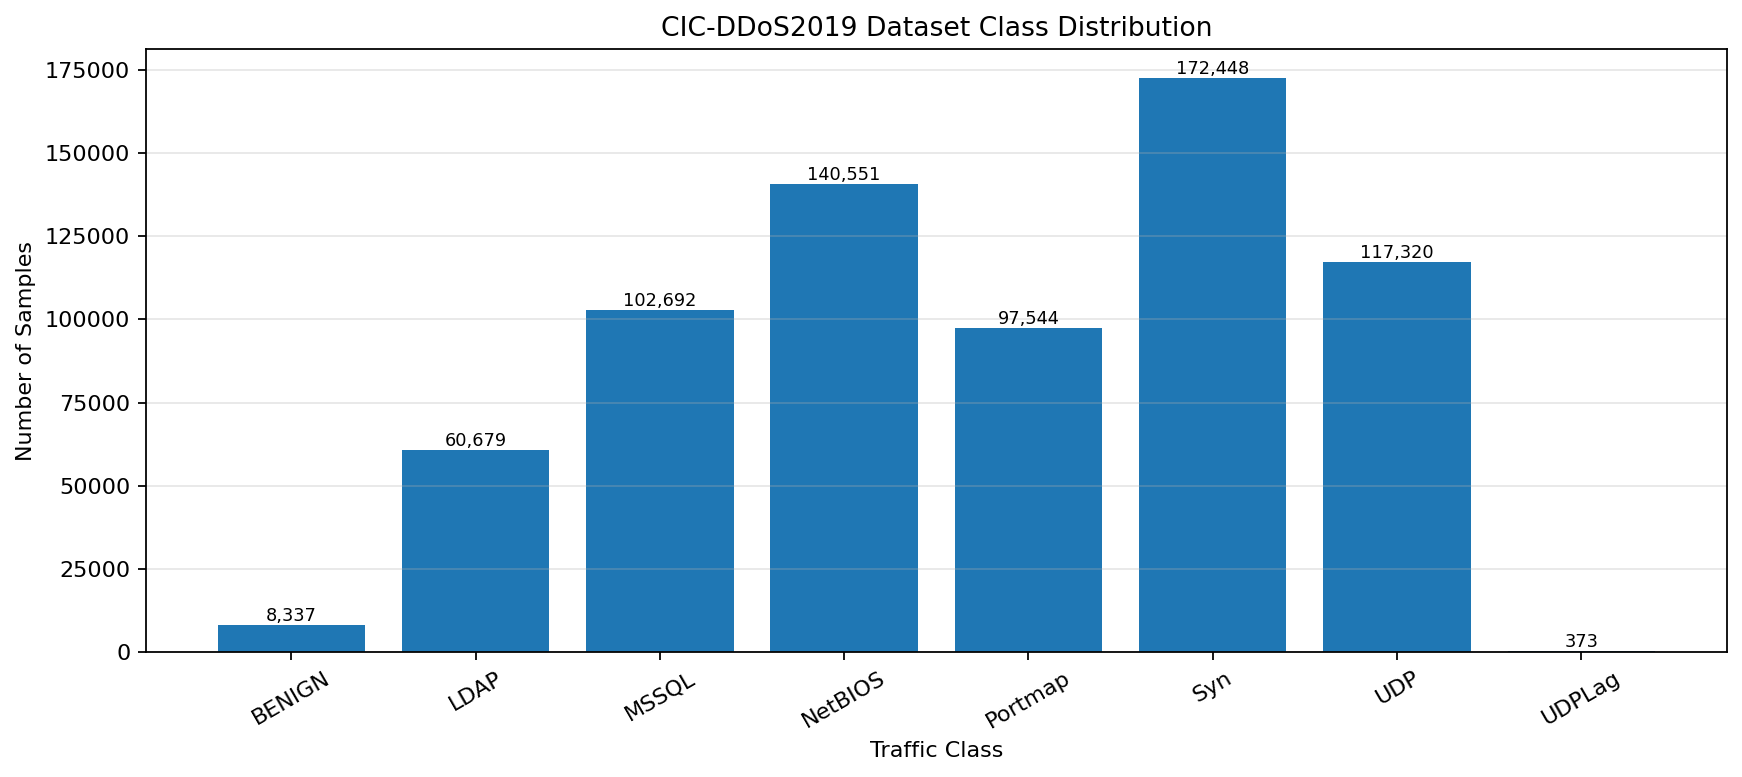

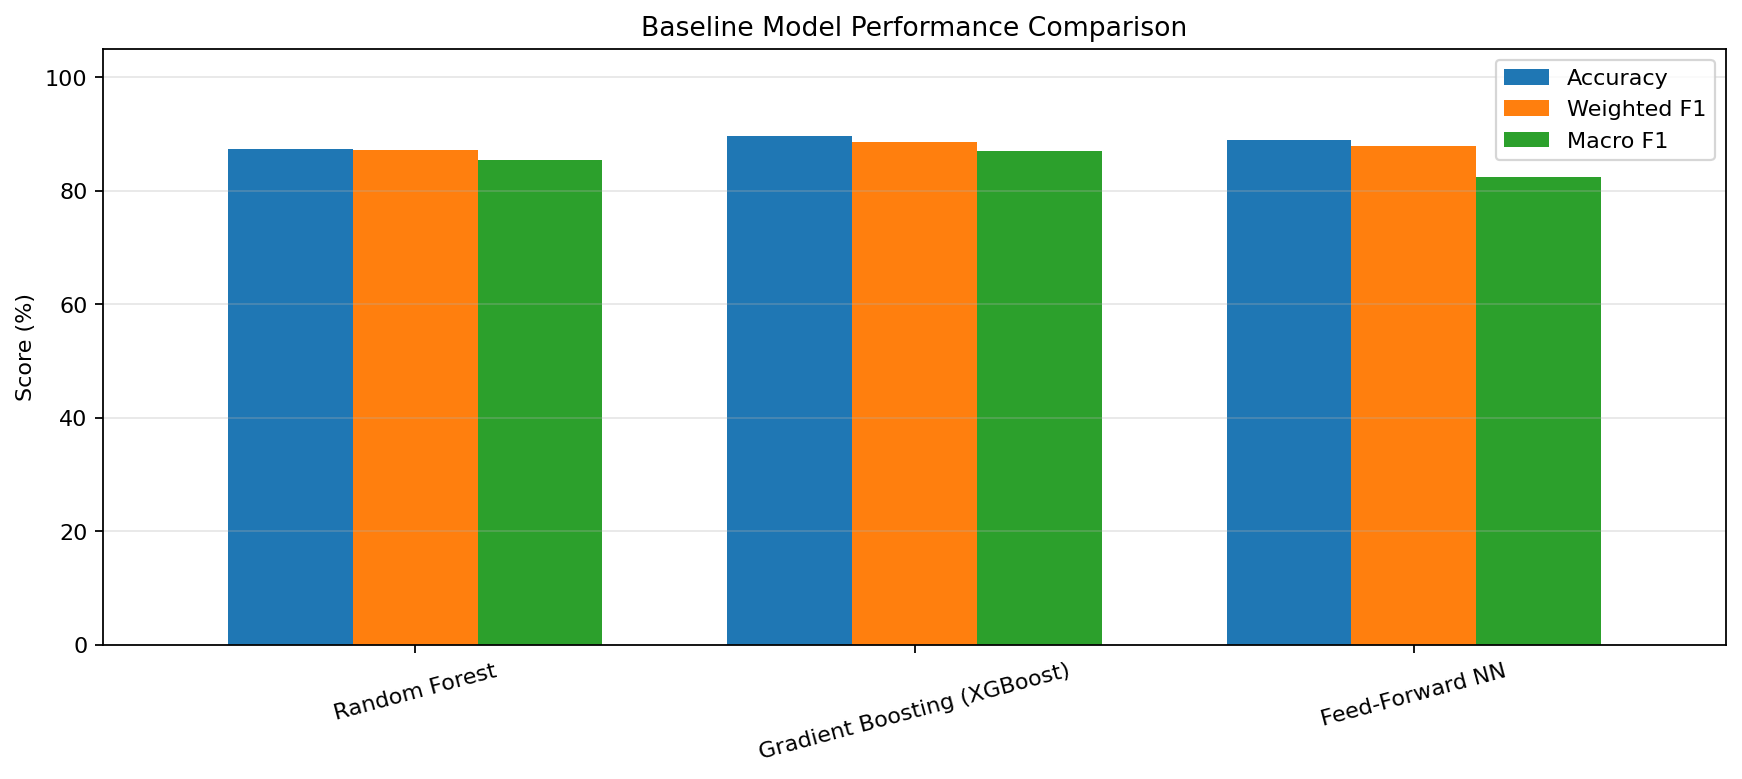

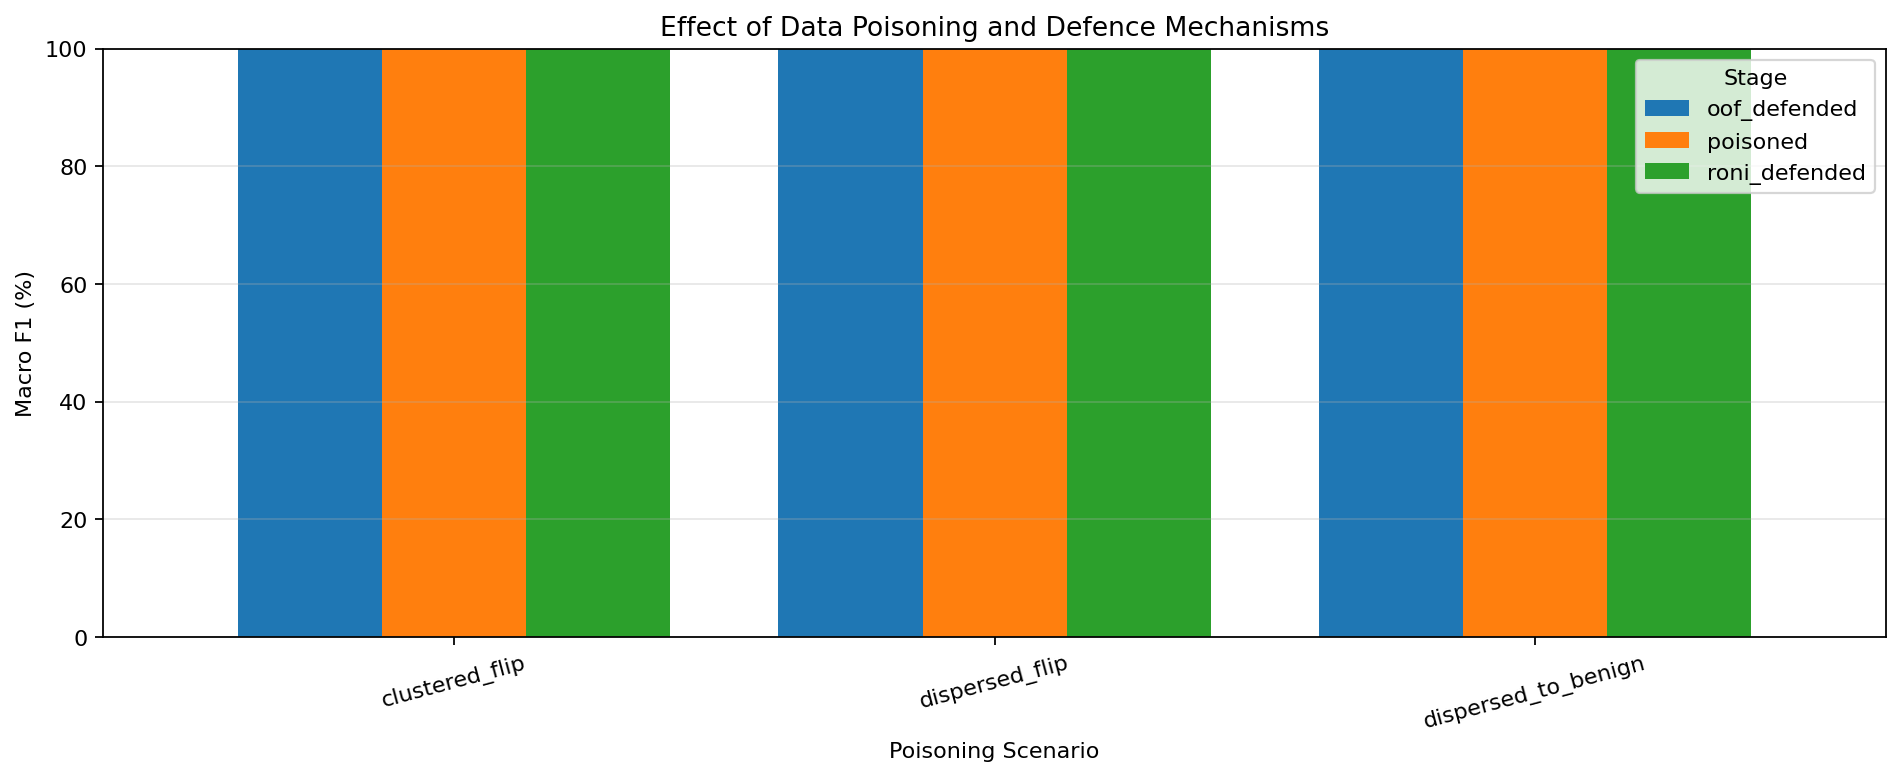

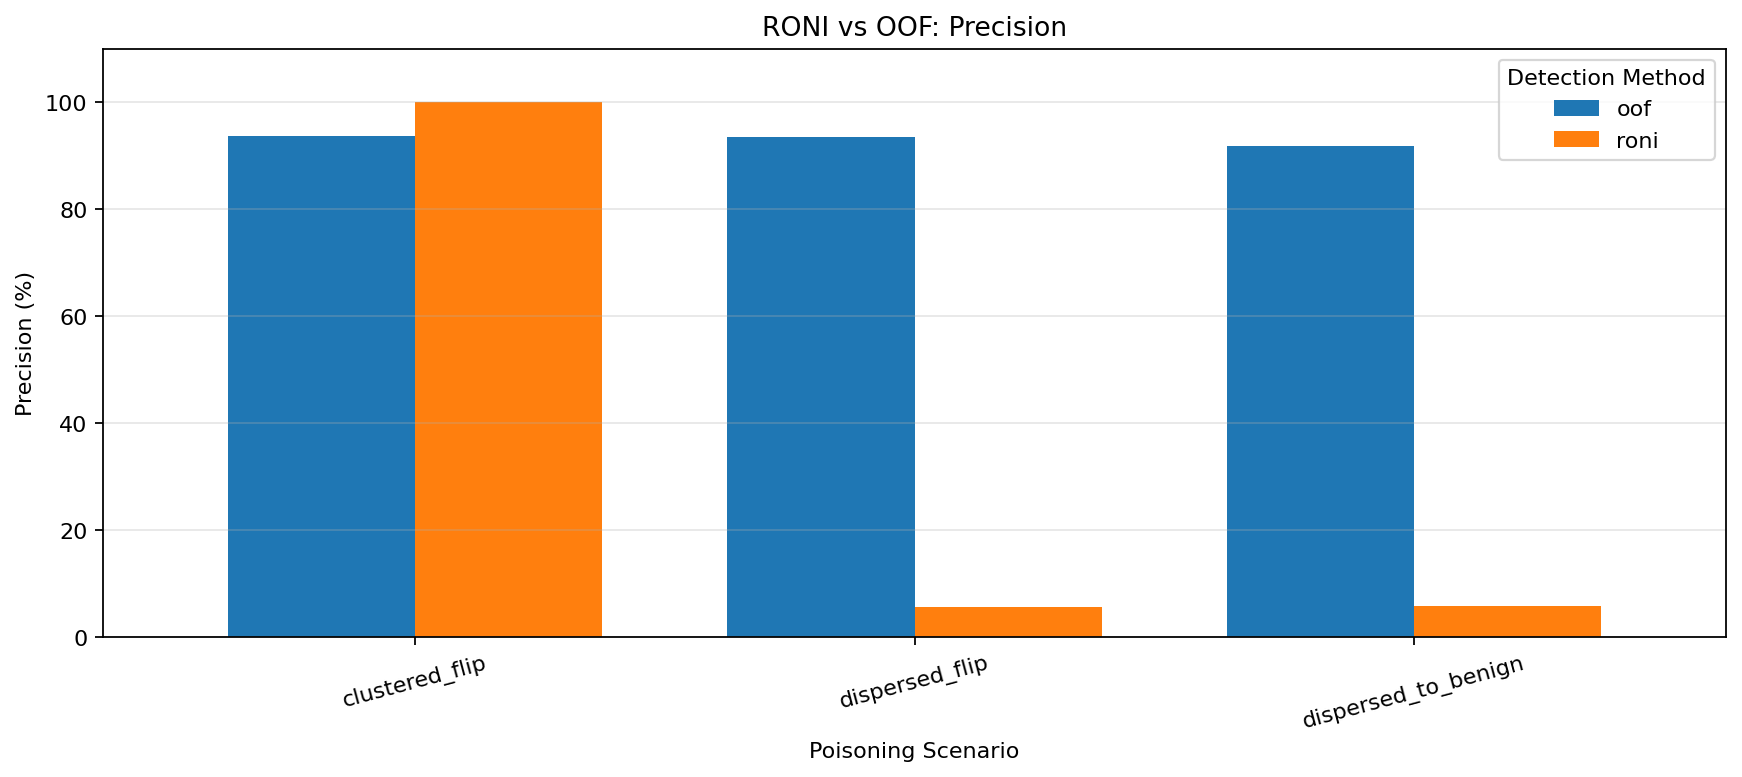

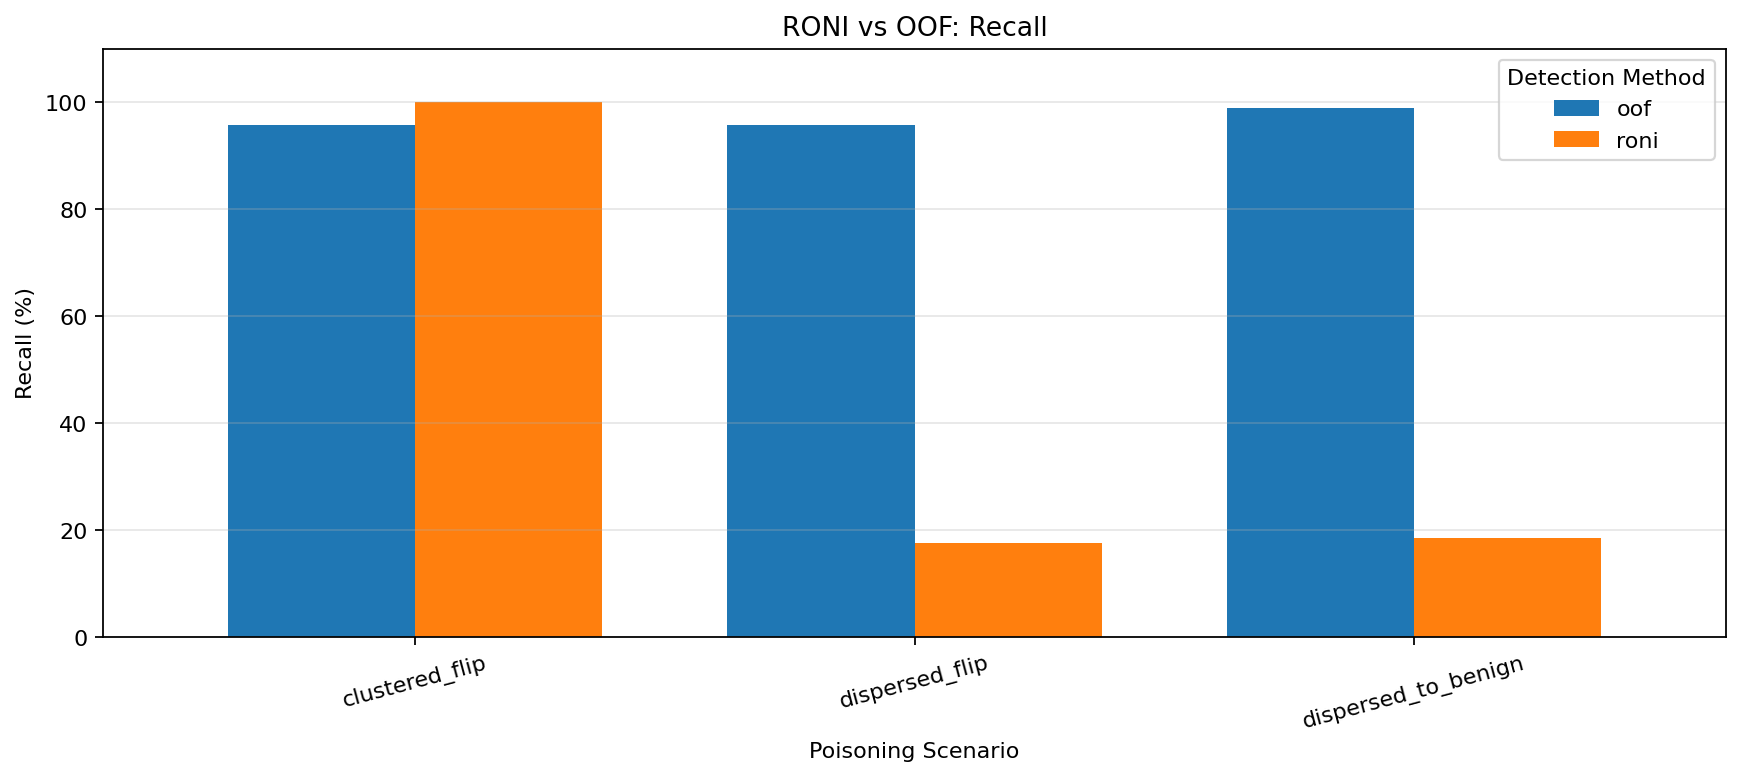

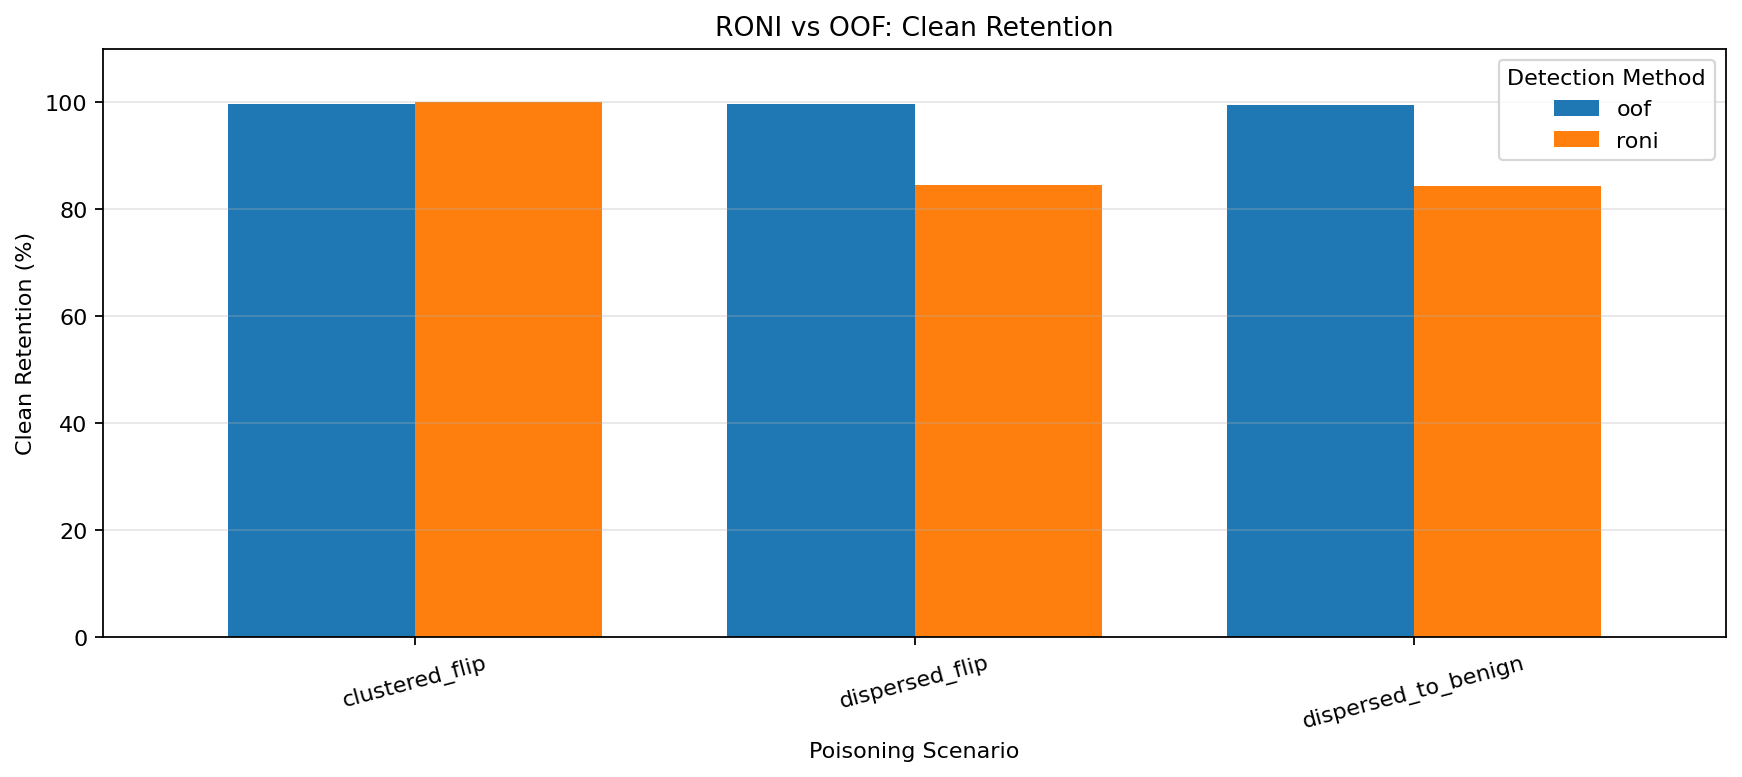

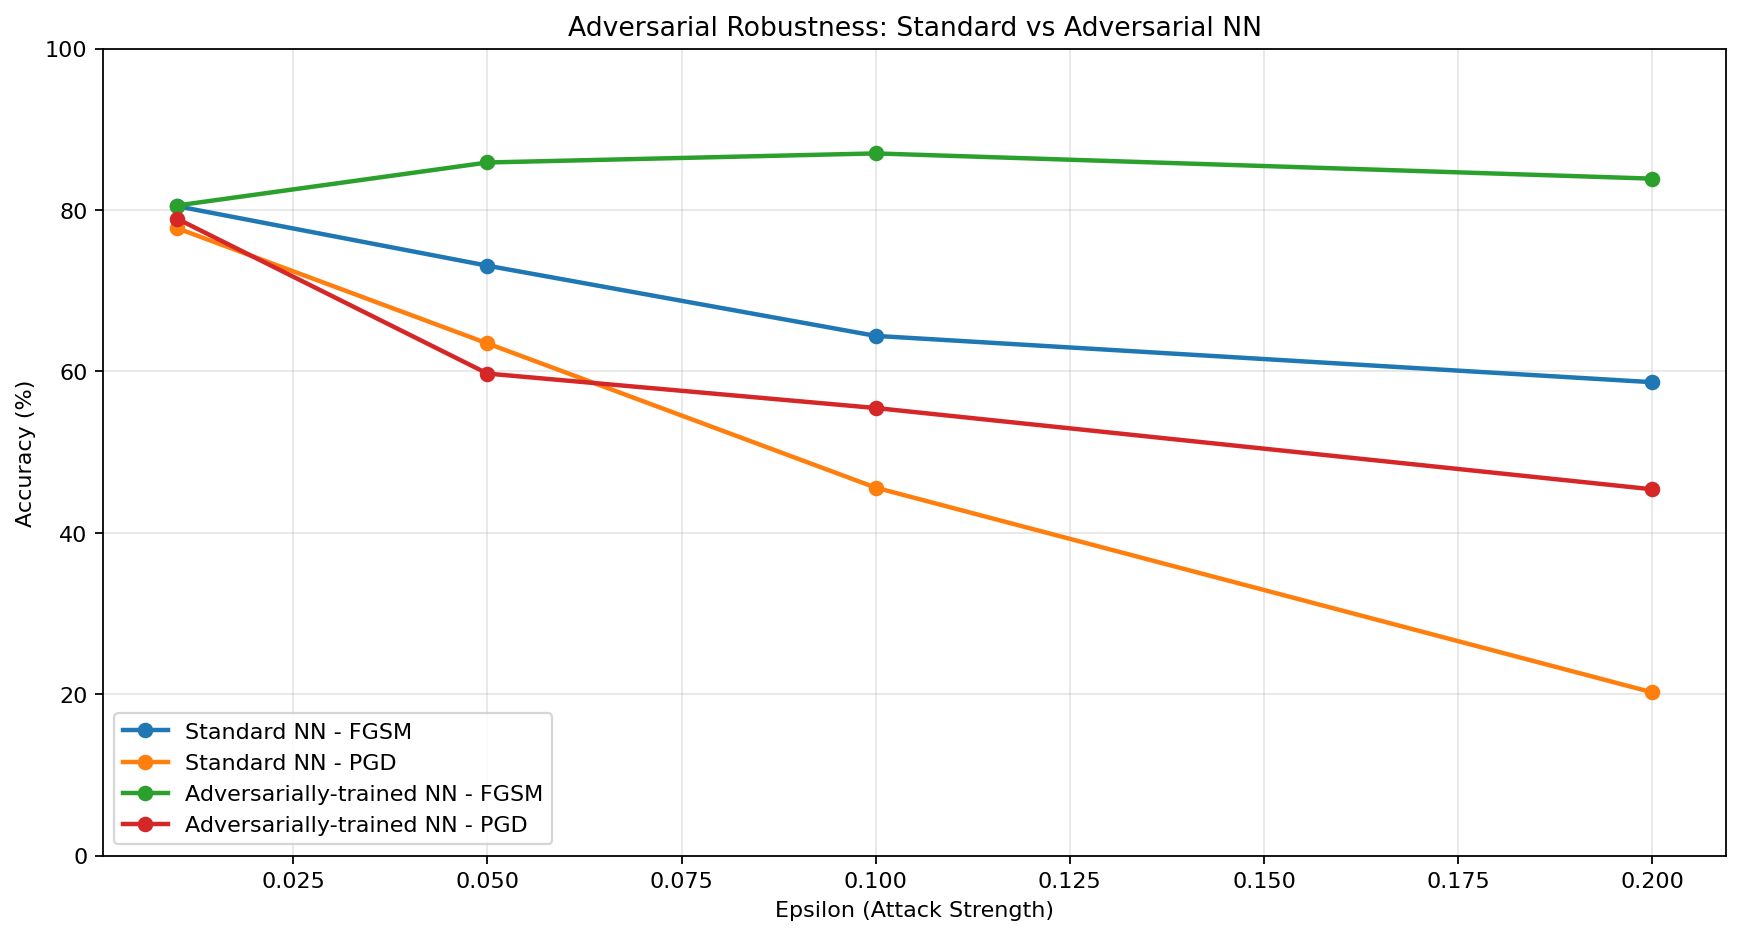

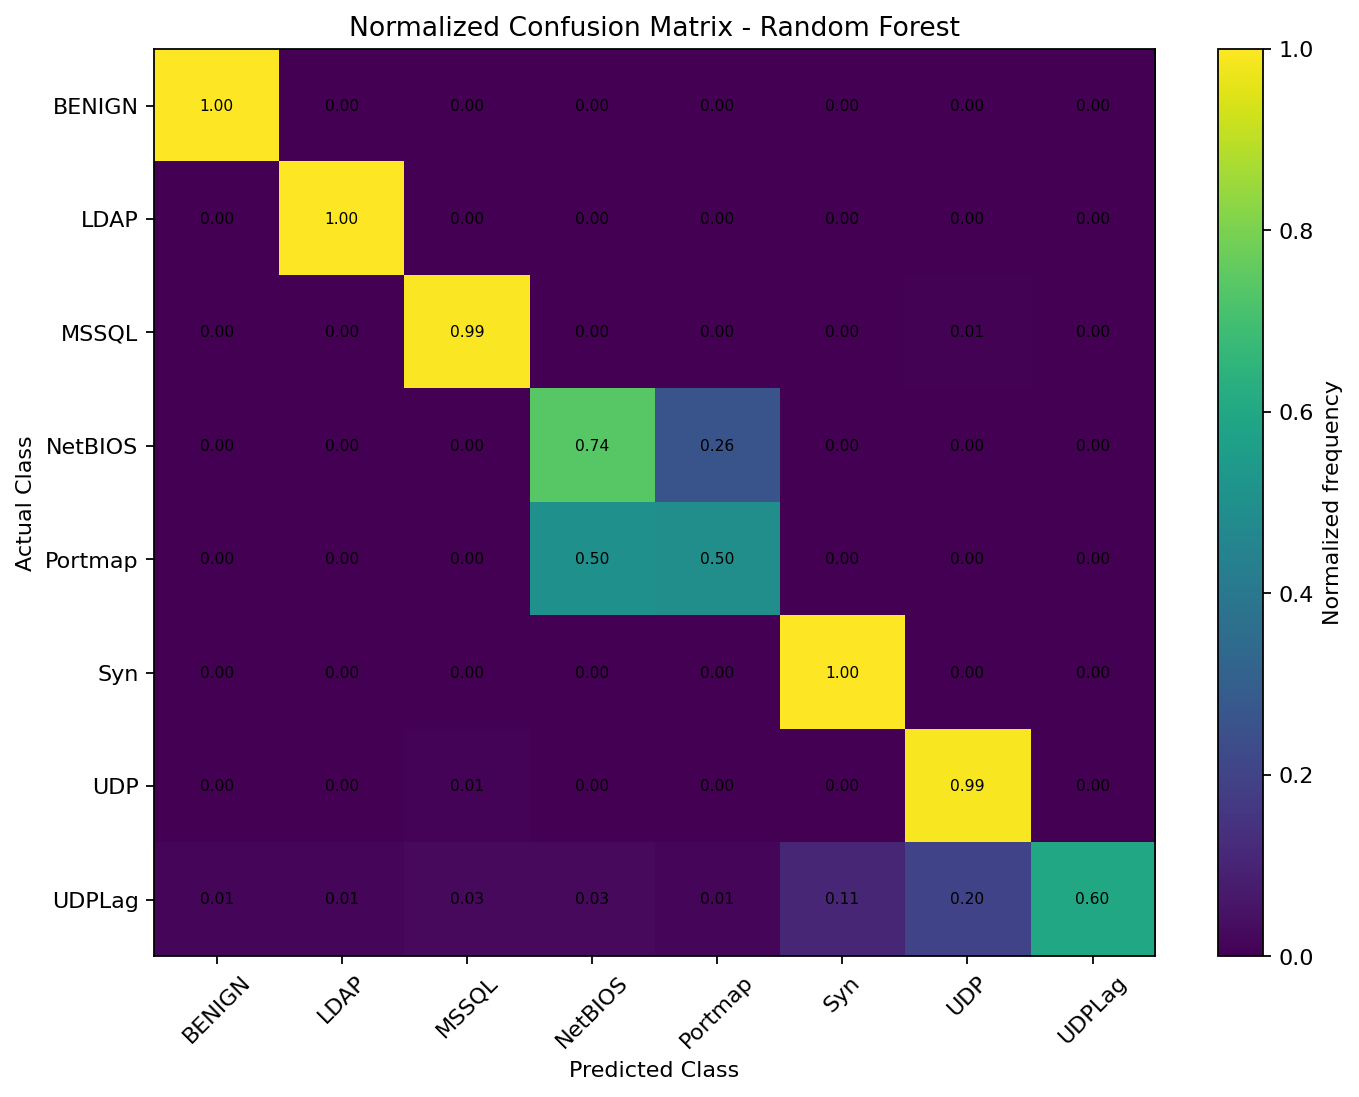

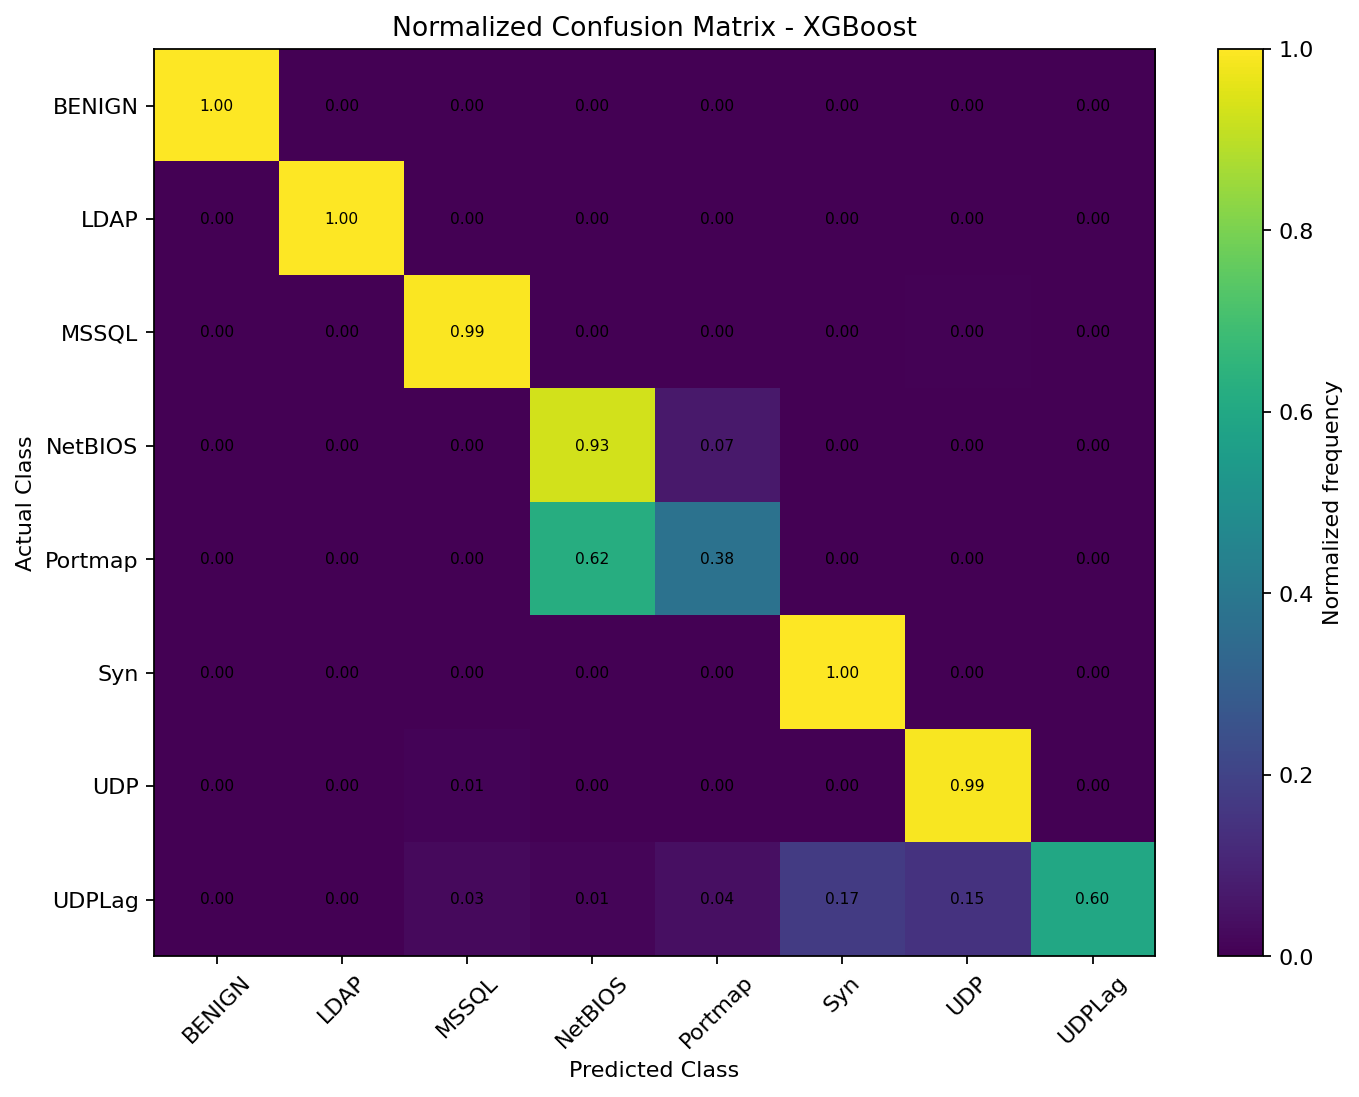

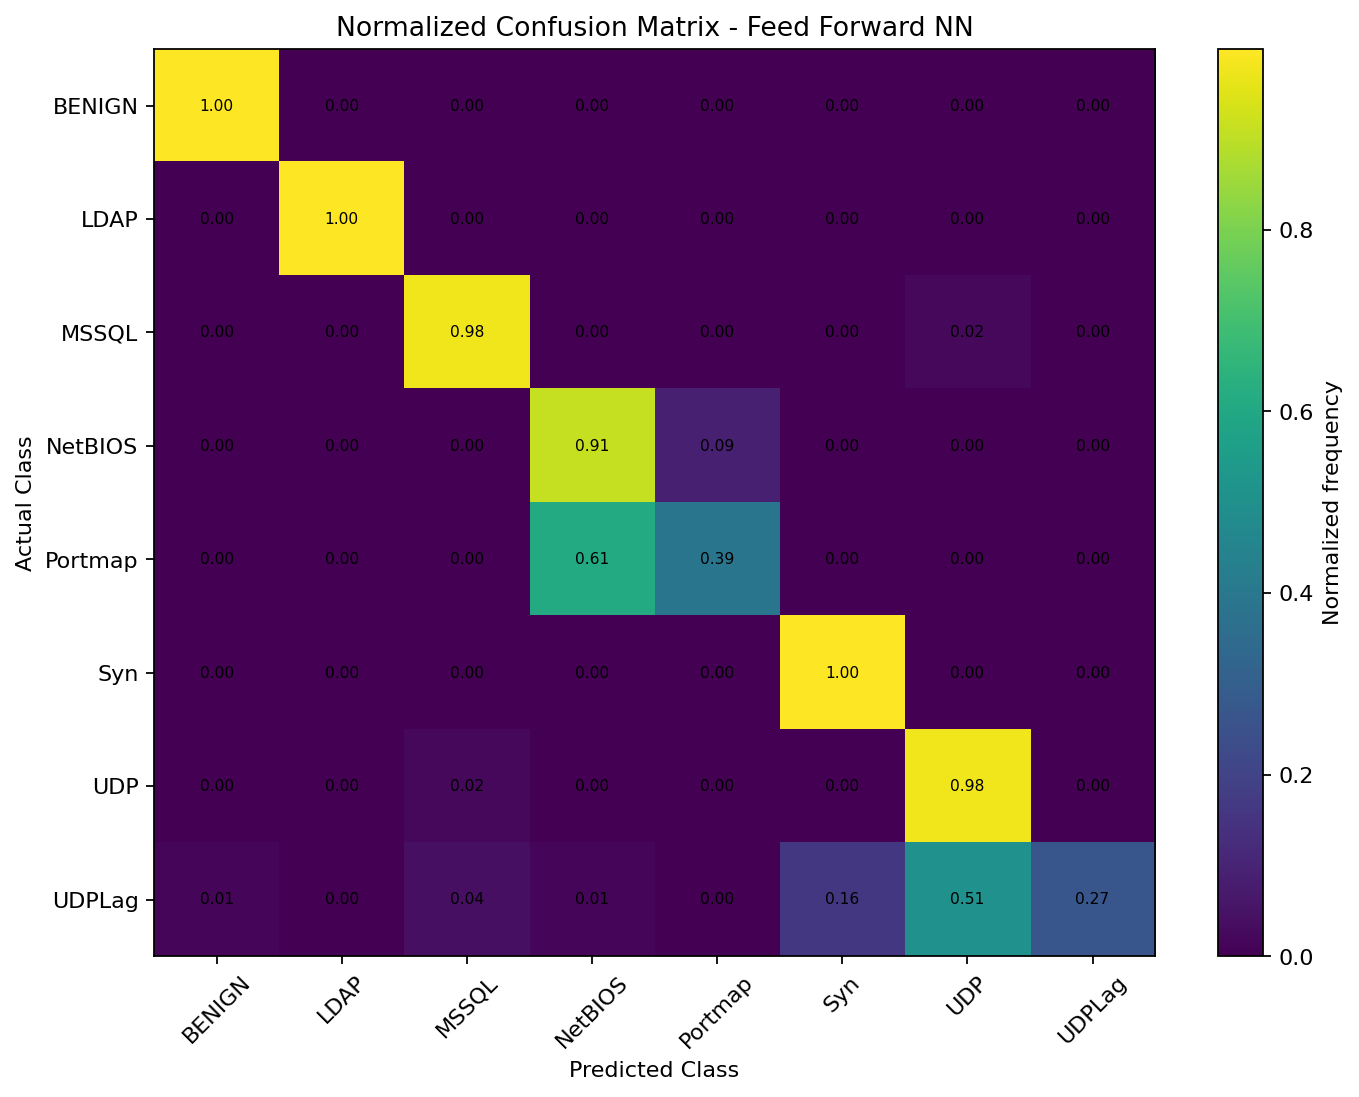


========== BASELINE RESULTS ==========


,Accuracy,Weighted F1,Macro F1
Model,,,
Random Forest,87.40,87.24,85.40
Gradient Boosting (XGBoost),89.67,88.64,87.09
Feed-Forward NN,88.89,87.96,82.38



========== DEFENCE RESULTS ==========


,Name,Accuracy,Weighted F1,Macro F1,Scenario,Stage
0,clean,89.688,88.662,87.343,clean,clean
1,clustered_flip/poisoned,89.677,88.648,87.143,clustered_flip,poisoned
2,clustered_flip/roni_defended,89.686,88.659,87.165,clustered_flip,roni_defended
3,clustered_flip/oof_defended,89.676,88.652,86.645,clustered_flip,oof_defended
4,dispersed_flip/poisoned,89.665,88.630,87.066,dispersed_flip,poisoned
5,dispersed_flip/roni_defended,89.661,88.632,87.066,dispersed_flip,roni_defended
6,dispersed_flip/oof_defended,89.670,88.640,86.891,dispersed_flip,oof_defended
7,dispersed_to_benign/poisoned,89.672,88.646,86.856,dispersed_to_benign,poisoned
8,dispersed_to_benign/roni_defended,89.674,88.642,87.099,dispersed_to_benign,roni_defended
9,dispersed_to_benign/oof_defended,89.665,88.648,86.954,dispersed_to_benign,oof_defended



========== POISON DETECTION RESULTS ==========


,Scenario,Method,Precision,Recall,Clean Retention
0,clustered_flip,roni,100.00,100.00,100.00
1,clustered_flip,oof,93.68,95.68,99.66
2,dispersed_flip,roni,5.65,17.56,84.57
3,dispersed_flip,oof,93.42,95.68,99.65
4,dispersed_to_benign,roni,5.85,18.56,84.28
5,dispersed_to_benign,oof,91.84,98.96,99.54



========== ADVERSARIAL RESULTS ==========


,Model,Attack,Epsilon,Accuracy
0,Standard NN,clean,0.00,88.89
1,Standard NN,FGSM,0.01,80.47
2,Standard NN,PGD,0.01,77.75
3,Standard NN,FGSM,0.05,73.09
4,Standard NN,PGD,0.05,63.46
5,Standard NN,FGSM,0.10,64.39
6,Standard NN,PGD,0.10,45.59
7,Standard NN,FGSM,0.20,58.65
8,Standard NN,PGD,0.20,20.23
9,Adversarially-trained NN,clean,0.00,84.97



All dashboard figures saved in: /kaggle/working/outputs


In [14]:

# ============================================================
# FINAL VISUALIZATION DASHBOARD
# Run after Section 7
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from IPython.display import display, Image
from pathlib import Path

OUT.mkdir(parents=True, exist_ok=True)

def show_plot(name):
    plt.tight_layout()
    path = OUT / name
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.close()
    display(Image(filename=str(path)))

# ------------------------------------------------------------
# 1. DATASET CLASS DISTRIBUTION
# ------------------------------------------------------------

class_counts = pd.Series(
    np.concatenate([y_train, y_test])
).value_counts().reindex(np.arange(len(CLASSES)), fill_value=0)

plt.figure(figsize=(11, 5))
plt.bar(CLASSES, class_counts.values)
plt.title("CIC-DDoS2019 Dataset Class Distribution")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

for i, v in enumerate(class_counts.values):
    plt.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=8)

show_plot("dashboard_1_class_distribution.png")


# ------------------------------------------------------------
# 2. BASELINE MODEL COMPARISON
# ------------------------------------------------------------

baseline = pd.DataFrame([
    {
        "Model": k.replace("baseline/", ""),
        "Accuracy": v["accuracy"] * 100,
        "Weighted F1": v["f1_w"] * 100,
        "Macro F1": v["f1_macro"] * 100
    }
    for k, v in RESULTS.items()
    if k.startswith("baseline/") and isinstance(v, dict)
    and "accuracy" in v
])

baseline = baseline.set_index("Model")

ax = baseline.plot.bar(figsize=(11, 5), width=0.75)
ax.set_title("Baseline Model Performance Comparison")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 105)
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15)
show_plot("dashboard_2_baseline_comparison.png")


# ------------------------------------------------------------
# 3. POISONING AND DEFENCE COMPARISON
# ------------------------------------------------------------

defence = pd.DataFrame([
    {
        "Name": k.replace("defense/", ""),
        "Accuracy": v["accuracy"] * 100,
        "Weighted F1": v["f1_w"] * 100,
        "Macro F1": v["f1_macro"] * 100
    }
    for k, v in RESULTS.items()
    if k.startswith("defense/")
    and isinstance(v, dict) and "accuracy" in v
])

defence["Scenario"] = defence["Name"].str.split("/").str[0]
defence["Stage"] = defence["Name"].str.split("/").str[-1]

pivot = defence[defence["Stage"] != "clean"].pivot(
    index="Scenario", columns="Stage", values="Macro F1"
) * 100

pivot.plot.bar(figsize=(12, 5), width=0.8)
plt.title("Effect of Data Poisoning and Defence Mechanisms")
plt.ylabel("Macro F1 (%)")
plt.xlabel("Poisoning Scenario")
plt.ylim(0, 100)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.legend(title="Stage")
show_plot("dashboard_3_poisoning_defence.png")


# ------------------------------------------------------------
# 4. RONI VS OOF DETECTION PERFORMANCE
# ------------------------------------------------------------

detection = pd.DataFrame([
    {
        "Scenario": k.split("/")[1],
        "Method": k.split("/")[2].replace("_detection", ""),
        "Precision": v["precision"] * 100,
        "Recall": v["recall"] * 100,
        "Clean Retention": v["clean_retention"] * 100
    }
    for k, v in RESULTS.items()
    if k.startswith("defense/") and k.endswith("_detection")
])

for metric in ["Precision", "Recall", "Clean Retention"]:
    plt.figure(figsize=(11, 5))
    p = detection.pivot(
        index="Scenario", columns="Method", values=metric
    )
    p.plot.bar(ax=plt.gca(), width=0.75)
    plt.title(f"RONI vs OOF: {metric}")
    plt.ylabel(f"{metric} (%)")
    plt.xlabel("Poisoning Scenario")
    plt.ylim(0, 110)
    plt.xticks(rotation=15)
    plt.grid(axis="y", alpha=0.3)
    plt.legend(title="Detection Method")
    show_plot(f"dashboard_4_{metric.lower().replace(' ', '_')}.png")


# ------------------------------------------------------------
# 5. ADVERSARIAL ROBUSTNESS COMPARISON
# ------------------------------------------------------------

adv = pd.DataFrame([
    {
        "Model": k.split("/")[1],
        "Attack": k.split("/")[2],
        "Epsilon": float(k.split("/")[3]),
        "Accuracy": v["accuracy"] * 100
    }
    for k, v in RESULTS.items()
    if k.startswith("adv/") and isinstance(v, dict)
    and "accuracy" in v
])

plt.figure(figsize=(11, 6))

for model in adv["Model"].unique():
    for attack in ["FGSM", "PGD"]:
        subset = adv[
            (adv["Model"] == model) &
            (adv["Attack"] == attack)
        ].sort_values("Epsilon")

        if len(subset):
            plt.plot(
                subset["Epsilon"],
                subset["Accuracy"],
                marker="o",
                linewidth=2,
                label=f"{model} - {attack}"
            )

plt.title("Adversarial Robustness: Standard vs Adversarial NN")
plt.xlabel("Epsilon (Attack Strength)")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
plt.grid(alpha=0.3)
plt.legend()
show_plot("dashboard_5_adversarial_robustness.png")


# ------------------------------------------------------------
# 6. CONFUSION MATRICES
# ------------------------------------------------------------

prediction_files = {
    "Random Forest": CKPT / "pred_rf.npy",
    "XGBoost": CKPT / "pred_xgb.npy",
    "Feed Forward NN": CKPT / "pred_nn.npy"
}

for model, path in prediction_files.items():

    if not path.exists():
        print(f"Missing prediction file: {path}")
        continue

    predictions = np.load(path)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(len(CLASSES)),
        normalize="true"
    )

    plt.figure(figsize=(9, 7))
    plt.imshow(cm, interpolation="nearest", aspect="auto")
    plt.colorbar(label="Normalized frequency")

    plt.xticks(np.arange(len(CLASSES)), CLASSES, rotation=45)
    plt.yticks(np.arange(len(CLASSES)), CLASSES)

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.title(f"Normalized Confusion Matrix - {model}")

    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            plt.text(j, i, f"{cm[i, j]:.2f}",
                     ha="center", va="center", fontsize=7)

    show_plot(
        "dashboard_6_confusion_" +
        model.lower().replace(" ", "_") + ".png"
    )


# ------------------------------------------------------------
# FINAL RESULTS TABLES
# ------------------------------------------------------------

print("\n========== BASELINE RESULTS ==========")
display(baseline.round(2))

print("\n========== DEFENCE RESULTS ==========")
display(defence.round(3))

print("\n========== POISON DETECTION RESULTS ==========")
display(detection.round(2))

print("\n========== ADVERSARIAL RESULTS ==========")
display(adv.round(2))

print("\nAll dashboard figures saved in:", OUT)


PROJECT VISUALIZATION DASHBOARD

 fig_adversarial.png


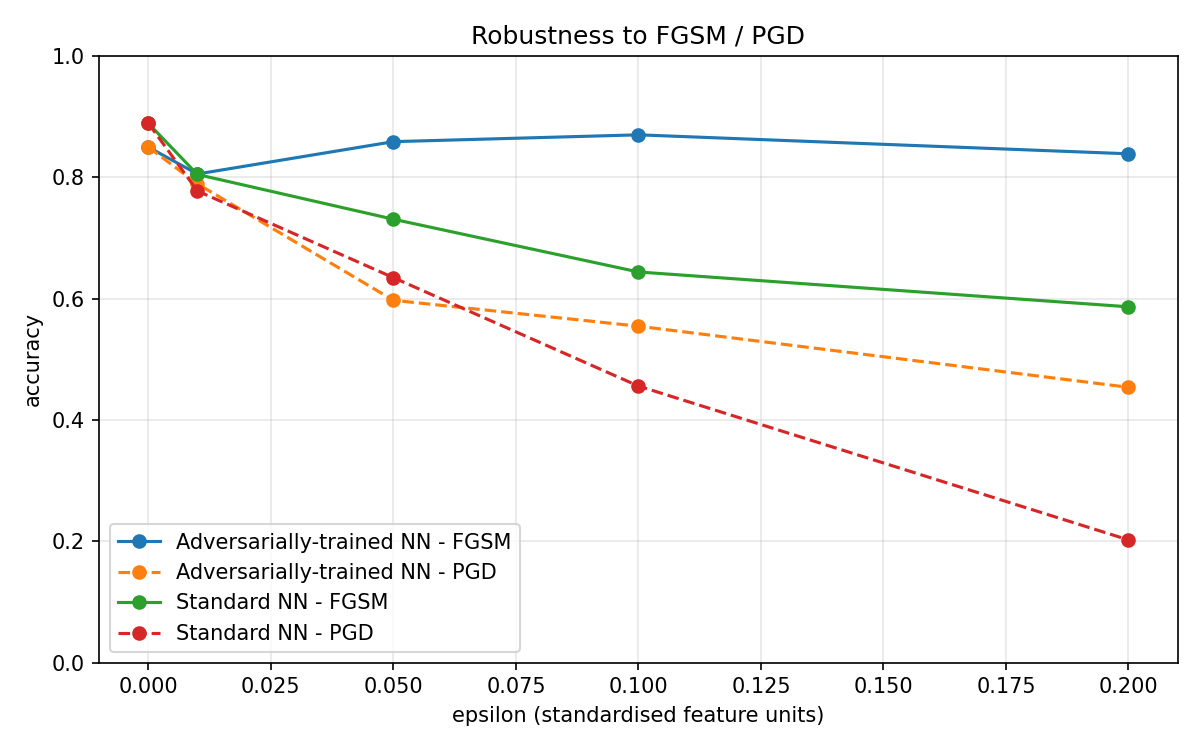


 fig_baseline.png


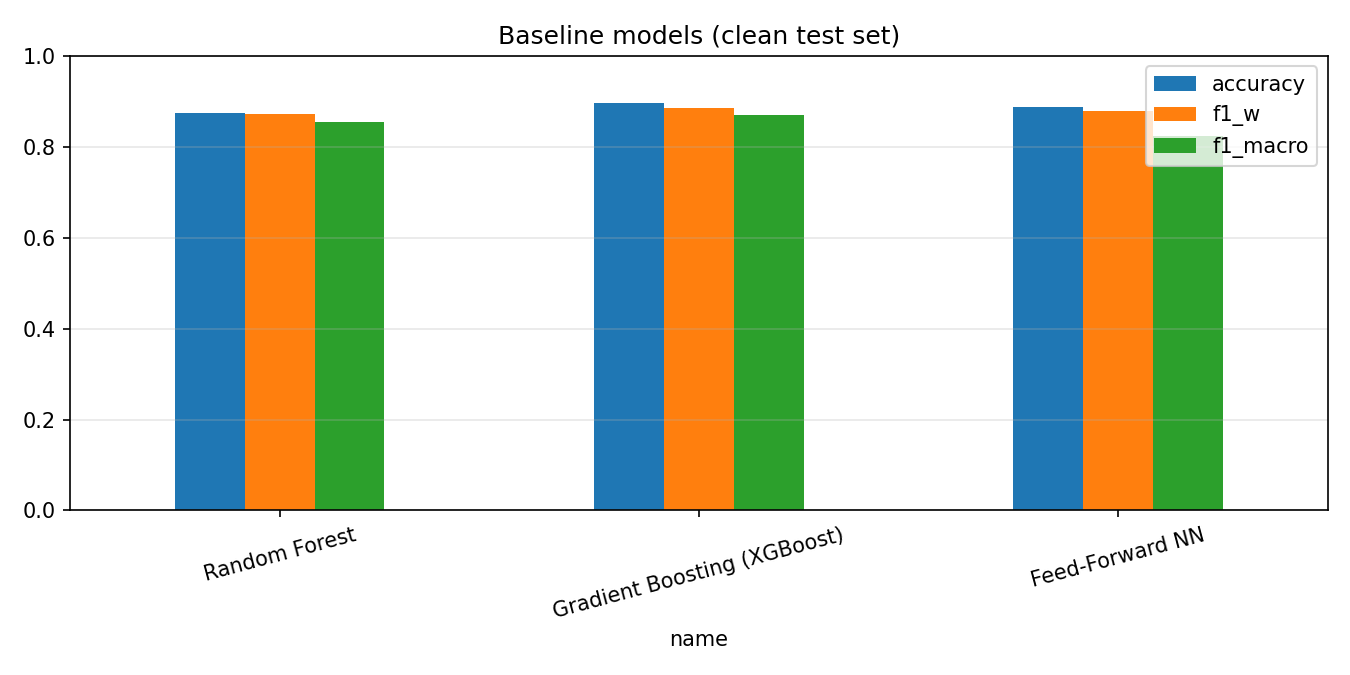


 fig_confusion_matrices.png


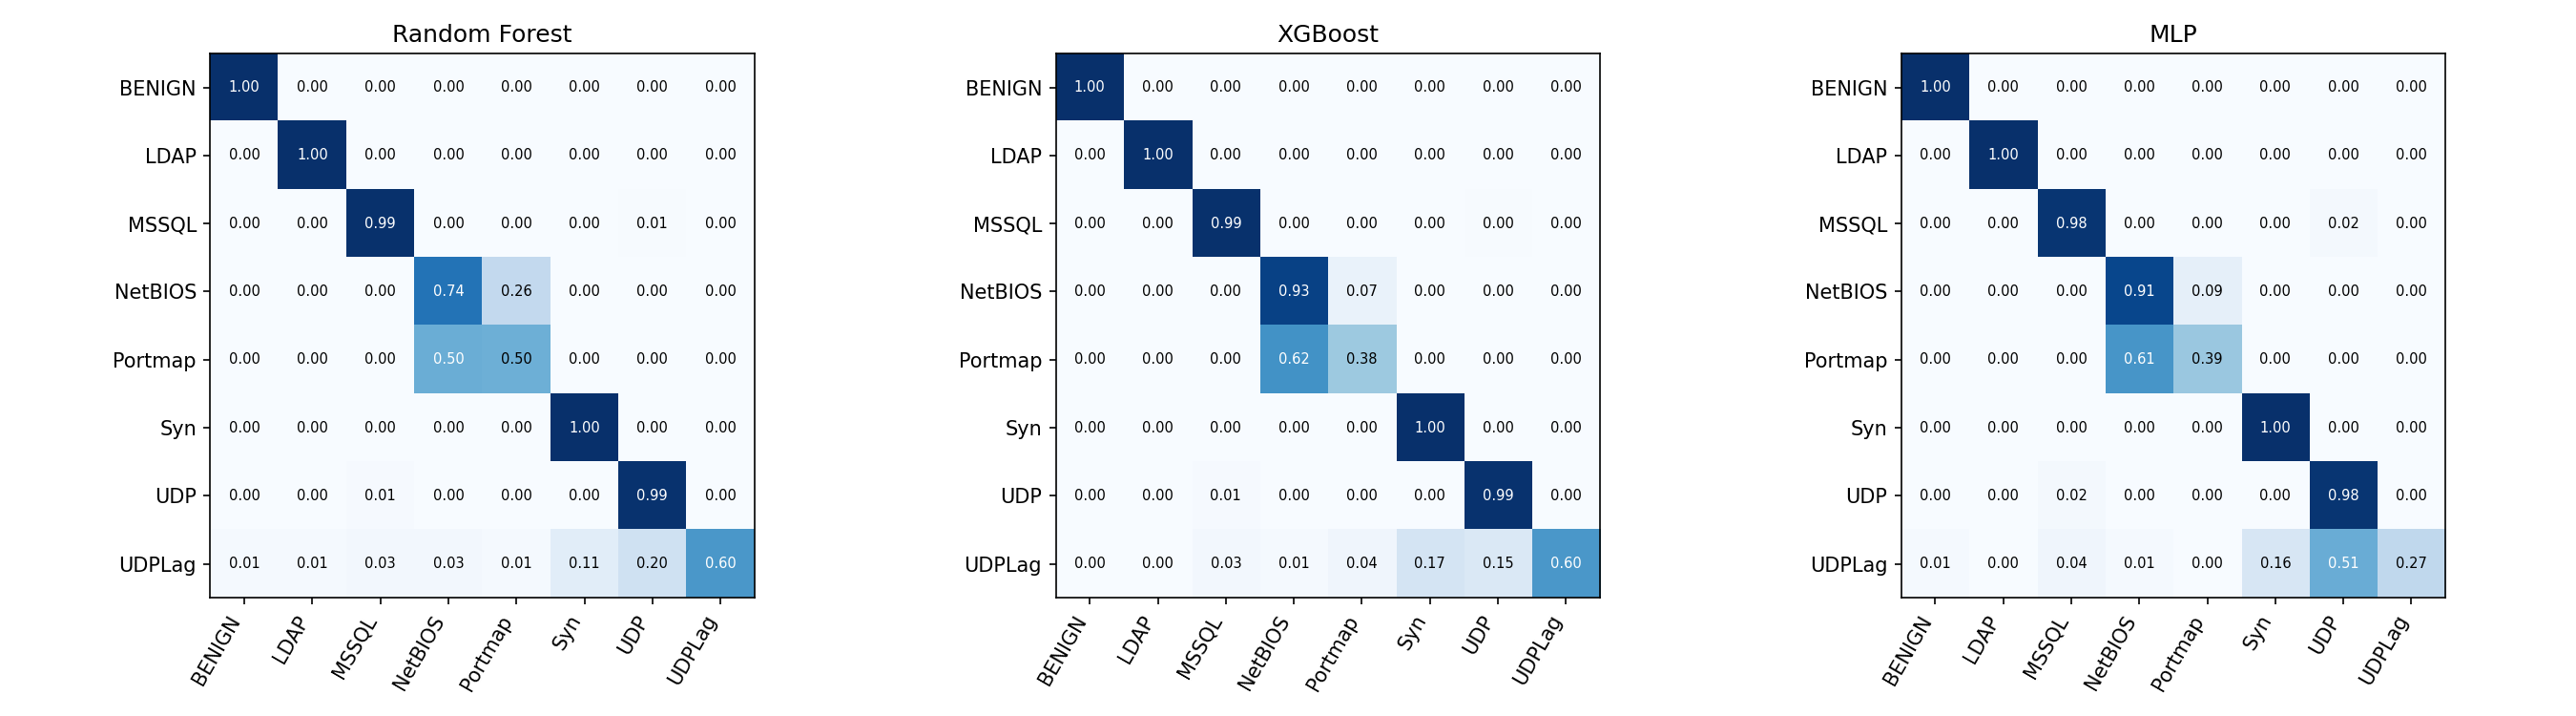


 fig_defences.png


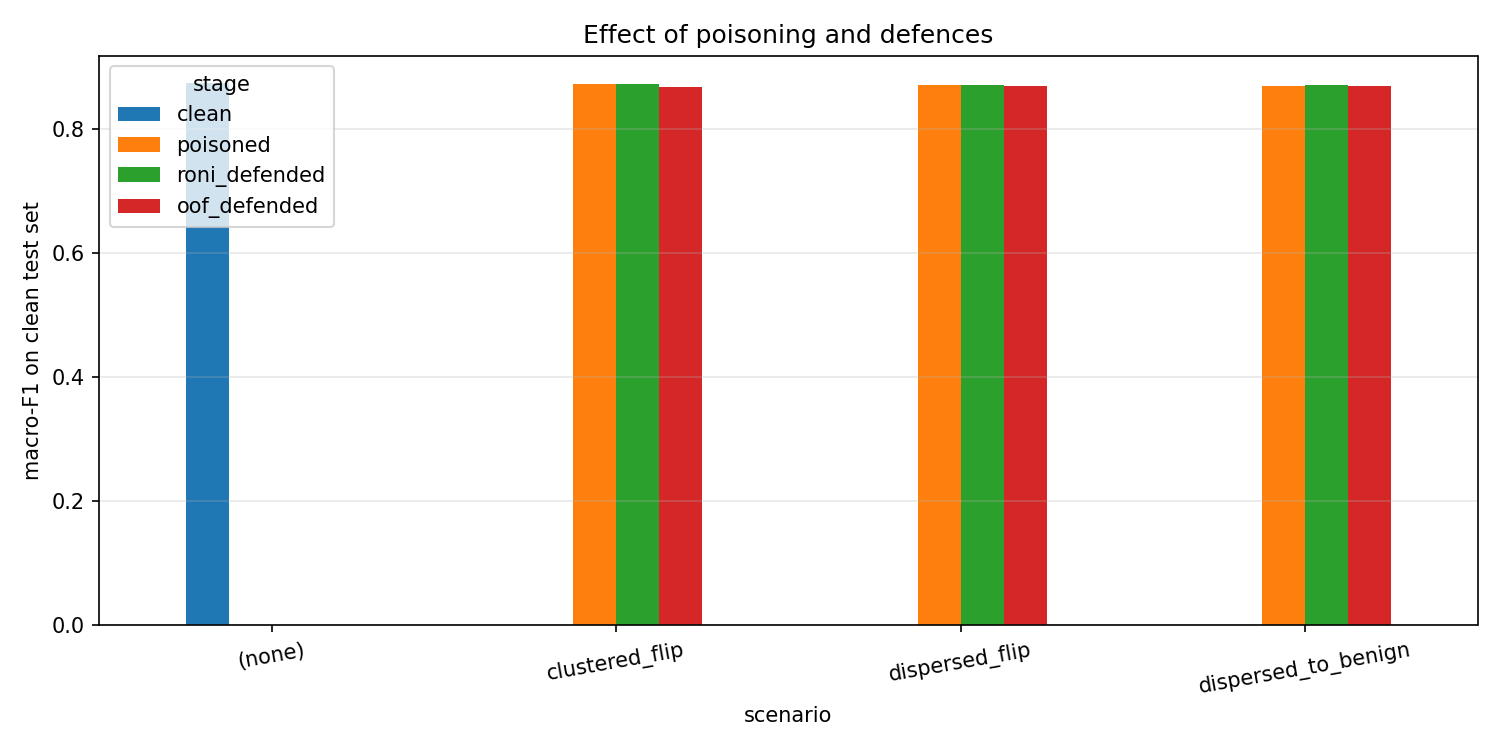


 fig_detection_tradeoff.png


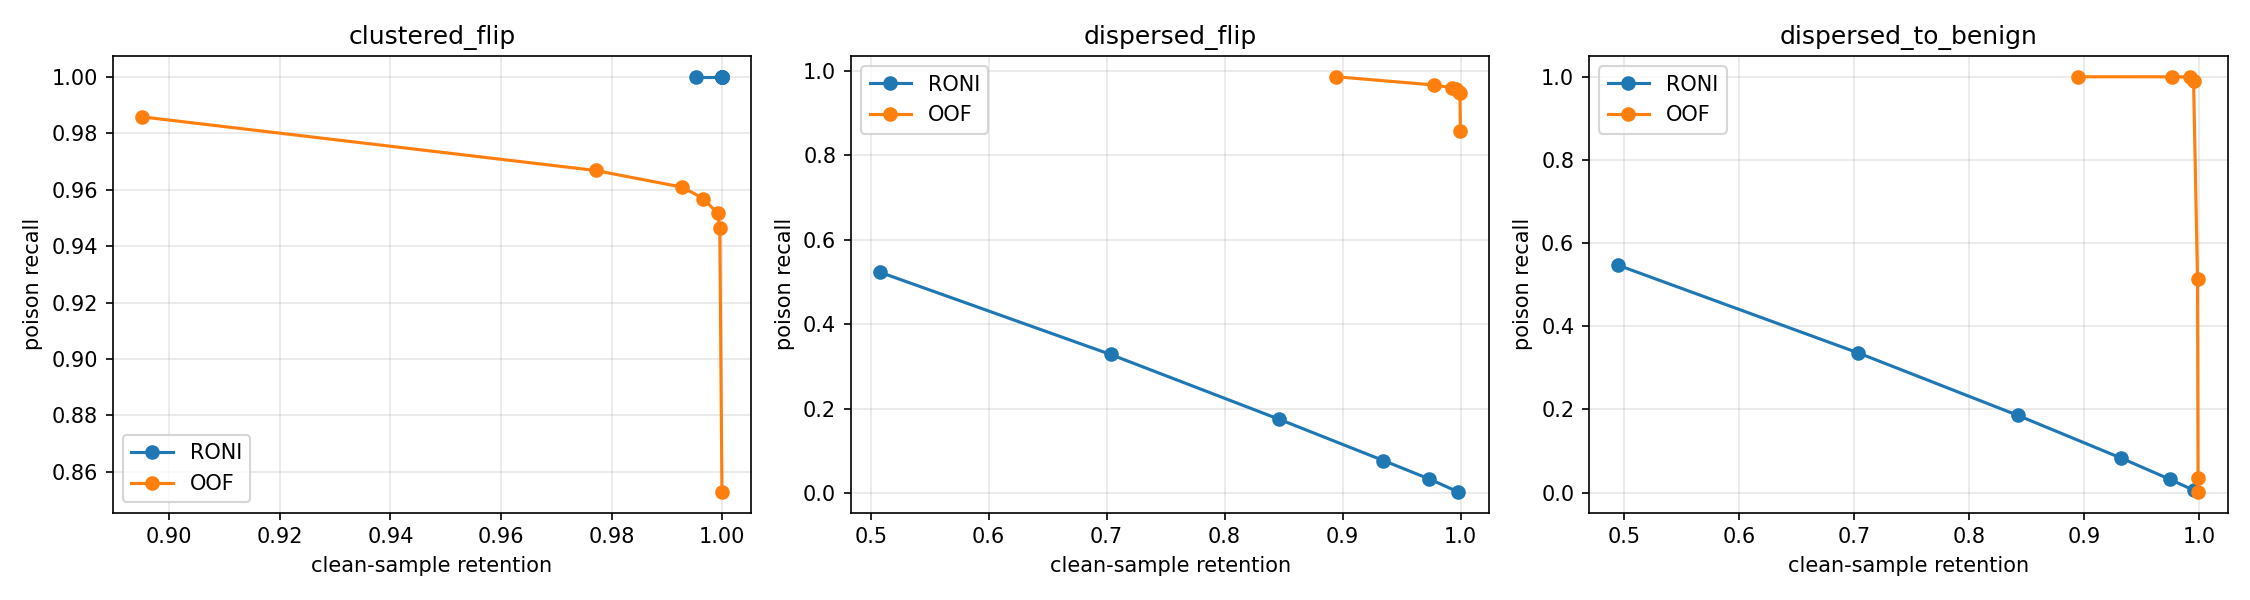


 fig_feature_importance.png


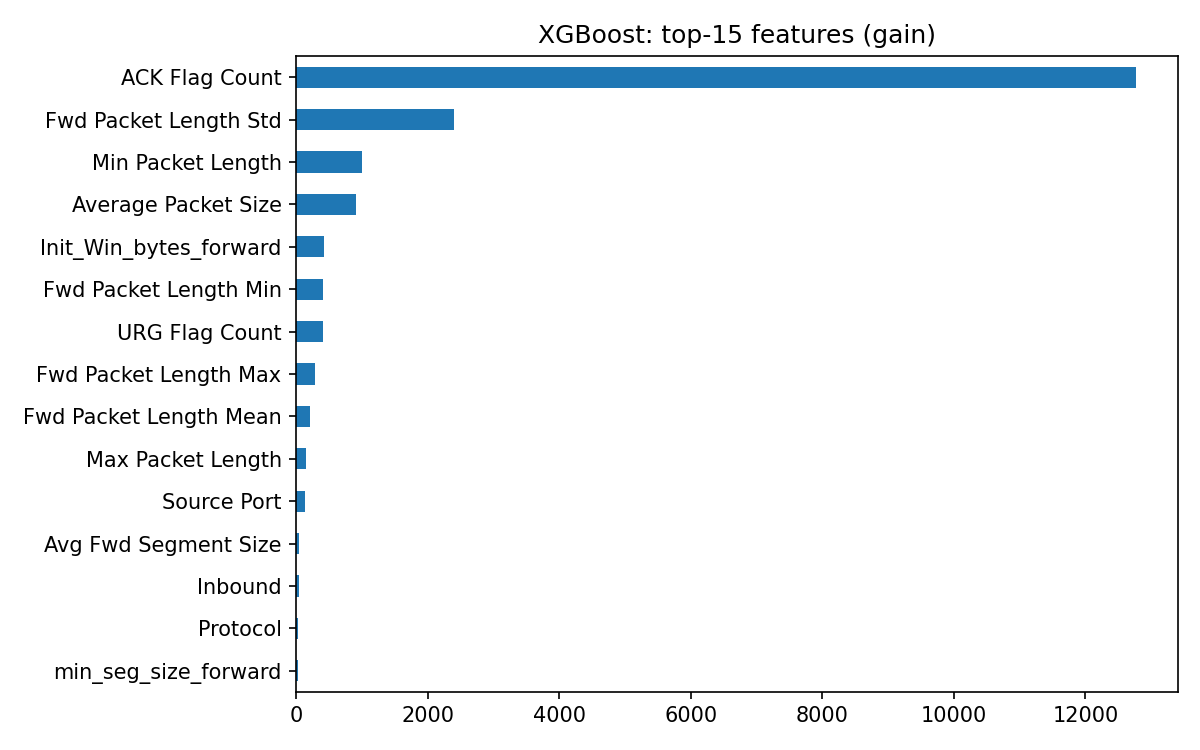

In [15]:
# Display all generated visualizations

from IPython.display import display, Image
from pathlib import Path

print("PROJECT VISUALIZATION DASHBOARD")

for file in sorted(OUT.glob("fig_*.png")):
    print("\n", file.name)
    display(Image(filename=str(file)))

In [16]:

# ============================================================
# 9. KAN MODEL - KOLMOGOROV ARNOLD NETWORK
# ============================================================

import tensorflow as tf
import numpy as np
import time
import gc
from pathlib import Path

L = tf.keras.layers

@tf.keras.utils.register_keras_serializable(package="NIDS")
class KANLinear(L.Layer):

    def __init__(self, units, grid_size=8, width=0.8, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.grid_size = grid_size
        self.width = width
        self.base = L.Dense(units, activation="silu")

    def build(self, input_shape):
        self.input_dim = int(input_shape[-1])

        self.centers = tf.linspace(
            -3.0, 3.0, self.grid_size
        )

        self.spline_weight = self.add_weight(
            name="spline_weight",
            shape=(self.input_dim, self.units, self.grid_size),
            initializer="glorot_uniform",
            trainable=True
        )

        self.bias = self.add_weight(
            name="bias",
            shape=(self.units,),
            initializer="zeros",
            trainable=True
        )

        super().build(input_shape)

    def call(self, inputs):

        # Gaussian radial basis functions
        x = tf.expand_dims(inputs, axis=-1)

        basis = tf.exp(
            -tf.square(
                (x - self.centers) / self.width
            )
        )

        # Learnable spline contribution
        spline_output = tf.einsum(
            "big,iog->bo",
            basis,
            self.spline_weight
        )

        # Base transformation + spline transformation
        return self.base(inputs) + spline_output + self.bias

    def get_config(self):
        config = super().get_config()
        config.update({
            "units": self.units,
            "grid_size": self.grid_size,
            "width": self.width
        })
        return config


def build_kan(n_in, n_classes):

    inputs = L.Input(shape=(n_in,))

    x = KANLinear(64, grid_size=8)(inputs)
    x = L.LayerNormalization()(x)
    x = L.Dropout(0.25)(x)

    x = KANLinear(32, grid_size=8)(x)
    x = L.LayerNormalization()(x)
    x = L.Dropout(0.20)(x)

    outputs = L.Dense(
        n_classes,
        activation="softmax"
    )(x)

    return tf.keras.Model(inputs, outputs, name="KAN")


kan_path = CKPT / "kan_baseline.keras"

if kan_path.exists():

    kan_model = tf.keras.models.load_model(kan_path)
    print("Loaded saved KAN model")

else:

    with timed("KAN training"):

        tf.keras.utils.set_random_seed(SEED)

        kan_model = build_kan(
            X_train.shape[1],
            K
        )

        kan_model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        callbacks = [
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            ),
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=2,
                min_lr=1e-5
            ),
            tf.keras.callbacks.CSVLogger(
                str(OUT / "kan_training_log.csv")
            )
        ]

        kan_model.fit(
            X_train,
            y_train,
            validation_split=0.10,
            epochs=S(40, 3),
            batch_size=S(2048, 256),
            callbacks=callbacks,
            verbose=2
        )

        kan_model.save(kan_path)


# Evaluate KAN

with timed("KAN evaluation"):

    kan_prob = kan_model.predict(
        X_test,
        batch_size=8192,
        verbose=0
    )

    kan_pred = np.argmax(kan_prob, axis=1)

    np.save(CKPT / "pred_kan.npy", kan_pred)

    record(
        "baseline/KAN",
        y_test,
        kan_pred,
        report=True
    )

print("KAN parameters:", kan_model.count_params())



▶ KAN training
Epoch 1/40
247/247 - 10s - 41ms/step - accuracy: 0.8028 - loss: 0.4088 - val_accuracy: 0.8387 - val_loss: 0.2853 - learning_rate: 0.0010
Epoch 2/40
247/247 - 1s - 4ms/step - accuracy: 0.8442 - loss: 0.2826 - val_accuracy: 0.8481 - val_loss: 0.2799 - learning_rate: 0.0010
Epoch 3/40
247/247 - 1s - 4ms/step - accuracy: 0.8489 - loss: 0.2698 - val_accuracy: 0.8478 - val_loss: 0.2915 - learning_rate: 0.0010
Epoch 4/40
247/247 - 1s - 4ms/step - accuracy: 0.8522 - loss: 0.2631 - val_accuracy: 0.8566 - val_loss: 0.2643 - learning_rate: 0.0010
Epoch 5/40
247/247 - 1s - 4ms/step - accuracy: 0.8538 - loss: 0.2584 - val_accuracy: 0.8585 - val_loss: 0.2589 - learning_rate: 0.0010
Epoch 6/40
247/247 - 1s - 4ms/step - accuracy: 0.8540 - loss: 0.2563 - val_accuracy: 0.8514 - val_loss: 0.2608 - learning_rate: 0.0010
Epoch 7/40
247/247 - 1s - 4ms/step - accuracy: 0.8553 - loss: 0.2532 - val_accuracy: 0.8542 - val_loss: 0.2777 - learning_rate: 0.0010
Epoch 8/40
247/247 - 1s - 4ms/step - 

In [17]:

# ============================================================
# 10. LSTM MODEL - FEATURE SEQUENCE CLASSIFICATION
# ============================================================

import tensorflow as tf
import numpy as np

# Convert tabular features into LSTM input format
# Shape: (samples, features, 1)

X_train_seq = X_train[..., np.newaxis]
X_test_seq = X_test[..., np.newaxis]

print("LSTM training shape:", X_train_seq.shape)
print("LSTM testing shape:", X_test_seq.shape)


def build_lstm(n_features, n_classes):

    inputs = L.Input(shape=(n_features, 1))

    x = L.LSTM(
        64,
        return_sequences=False
    )(inputs)

    x = L.Dropout(0.3)(x)

    x = L.Dense(
        64,
        activation="relu"
    )(x)

    x = L.Dropout(0.2)(x)

    outputs = L.Dense(
        n_classes,
        activation="softmax"
    )(x)

    return tf.keras.Model(
        inputs,
        outputs,
        name="LSTM"
    )


lstm_path = CKPT / "lstm_baseline.keras"

if lstm_path.exists():

    lstm_model = tf.keras.models.load_model(lstm_path)
    print("Loaded saved LSTM model")

else:

    with timed("LSTM training"):

        tf.keras.utils.set_random_seed(SEED)

        lstm_model = build_lstm(
            X_train.shape[1],
            K
        )

        lstm_model.compile(
            optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        callbacks = [
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True
            ),
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                patience=2,
                factor=0.5,
                min_lr=1e-5
            ),
            tf.keras.callbacks.CSVLogger(
                str(OUT / "lstm_training_log.csv")
            )
        ]

        lstm_model.fit(
            X_train_seq,
            y_train,
            validation_split=0.10,
            epochs=S(35, 3),
            batch_size=S(2048, 256),
            callbacks=callbacks,
            verbose=2
        )

        lstm_model.save(lstm_path)


# Evaluate LSTM

with timed("LSTM evaluation"):

    lstm_prob = lstm_model.predict(
        X_test_seq,
        batch_size=8192,
        verbose=0
    )

    lstm_pred = np.argmax(lstm_prob, axis=1)

    np.save(CKPT / "pred_lstm.npy", lstm_pred)

    record(
        "baseline/LSTM",
        y_test,
        lstm_pred,
        report=True
    )

print("LSTM parameters:", lstm_model.count_params())


LSTM training shape: (559955, 69, 1)
LSTM testing shape: (139989, 69, 1)

▶ LSTM training
Epoch 1/35
247/247 - 9s - 38ms/step - accuracy: 0.6636 - loss: 0.7750 - val_accuracy: 0.7596 - val_loss: 0.5907 - learning_rate: 0.0010
Epoch 2/35
247/247 - 6s - 23ms/step - accuracy: 0.8163 - loss: 0.3732 - val_accuracy: 0.8369 - val_loss: 0.3189 - learning_rate: 0.0010
Epoch 3/35
247/247 - 6s - 25ms/step - accuracy: 0.8318 - loss: 0.3311 - val_accuracy: 0.8317 - val_loss: 0.3193 - learning_rate: 0.0010
Epoch 4/35
247/247 - 6s - 23ms/step - accuracy: 0.8360 - loss: 0.3190 - val_accuracy: 0.8345 - val_loss: 0.3162 - learning_rate: 0.0010
Epoch 5/35
247/247 - 6s - 23ms/step - accuracy: 0.8380 - loss: 0.3117 - val_accuracy: 0.8333 - val_loss: 0.3180 - learning_rate: 0.0010
Epoch 6/35
247/247 - 6s - 22ms/step - accuracy: 0.8391 - loss: 0.3061 - val_accuracy: 0.8225 - val_loss: 0.3302 - learning_rate: 0.0010
Epoch 7/35
247/247 - 5s - 22ms/step - accuracy: 0.8416 - loss: 0.3001 - val_accuracy: 0.8405 -

In [18]:

# ============================================================
# 11. FIVE MODEL COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

model_results = pd.DataFrame([
    {
        "Model": name,
        "Accuracy": RESULTS[f"baseline/{name}"]["accuracy"] * 100,
        "Weighted F1": RESULTS[f"baseline/{name}"]["f1_w"] * 100,
        "Macro F1": RESULTS[f"baseline/{name}"]["f1_macro"] * 100
    }
    for name in [
        "Random Forest",
        "Gradient Boosting (XGBoost)",
        "Feed-Forward NN",
        "KAN",
        "LSTM"
    ]
    if f"baseline/{name}" in RESULTS
])

display(model_results.round(3))

model_results.to_csv(
    OUT / "five_model_comparison.csv",
    index=False
)

ax = model_results.set_index("Model").plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Performance Comparison: Five NIDS Models")
plt.ylabel("Performance (%)")
plt.xlabel("Model")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    OUT / "fig_five_model_comparison.png",
    dpi=160
)

plt.show()



,Model,Accuracy,Weighted F1,Macro F1
0,Random Forest,87.402,87.243,85.398
1,Gradient Boosting (XGBoost),89.674,88.642,87.091
2,Feed-Forward NN,88.888,87.959,82.380
3,KAN,85.858,84.930,75.408
4,LSTM,85.028,79.814,70.654


In [19]:

# ============================================================
# 12. INFERENCE TIME AND THROUGHPUT BENCHMARK
# ============================================================

import time
import joblib
import xgboost as xgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load original trained models
rf_model = joblib.load(CKPT / "rf_baseline.joblib")

xgb_model = xgb.Booster()
xgb_model.load_model(str(CKPT / "xgb_baseline.json"))

# Prediction functions
def predict_rf(X):
    return rf_model.predict(X)


def predict_xgb(X):
    dmatrix = xgb.DMatrix(X)
    return np.argmax(xgb_model.predict(dmatrix), axis=1)


def predict_nn(X):
    result = nn_model(tf.convert_to_tensor(X), training=False)
    return np.argmax(result.numpy(), axis=1)


def predict_kan(X):
    result = kan_model(tf.convert_to_tensor(X), training=False)
    return np.argmax(result.numpy(), axis=1)


def predict_lstm(X):
    X_seq = X[..., np.newaxis]
    result = lstm_model(tf.convert_to_tensor(X_seq), training=False)
    return np.argmax(result.numpy(), axis=1)


models = {
    "Random Forest": predict_rf,
    "XGBoost": predict_xgb,
    "Feed Forward NN": predict_nn,
    "KAN": predict_kan,
    "LSTM": predict_lstm
}


# Benchmark configuration
BATCH_SIZES = [1, 16, 64, 256, 1024, 4096]
WARMUP = 5
REPEATS = 30

benchmark_results = []


def benchmark_inference(model_name, predict_fn, X, batch_size):

    batch = X[:batch_size]

    # Warmup: initialize model execution and device kernels
    for _ in range(WARMUP):
        predict_fn(batch)

    latencies = []

    for _ in range(REPEATS):

        start = time.perf_counter()

        predict_fn(batch)

        end = time.perf_counter()

        latency_ms = (end - start) * 1000
        latencies.append(latency_ms)

    latencies = np.array(latencies)

    p50 = np.percentile(latencies, 50)
    p95 = np.percentile(latencies, 95)
    mean = np.mean(latencies)

    throughput = batch_size / (p50 / 1000)

    return {
        "Model": model_name,
        "Batch Size": batch_size,
        "Mean Latency (ms)": mean,
        "P50 Latency (ms)": p50,
        "P95 Latency (ms)": p95,
        "Latency per Sample (ms)": p50 / batch_size,
        "Throughput (samples/sec)": throughput
    }


# Run benchmark
for model_name, predict_fn in models.items():

    print(f"\nBenchmarking: {model_name}")

    for bs in BATCH_SIZES:

        if bs > len(X_test):
            continue

        result = benchmark_inference(
            model_name,
            predict_fn,
            X_test,
            bs
        )

        benchmark_results.append(result)

        print(
            f"Batch={bs:5d} | "
            f"P50={result['P50 Latency (ms)']:.3f} ms | "
            f"P95={result['P95 Latency (ms)']:.3f} ms | "
            f"Throughput={result['Throughput (samples/sec)']:.1f} samples/sec"
        )


# Save results
benchmark_df = pd.DataFrame(benchmark_results)

benchmark_df.to_csv(
    OUT / "inference_benchmark.csv",
    index=False
)

print("\n========== INFERENCE BENCHMARK RESULTS ==========")

display(
    benchmark_df.round(3)
)



Benchmarking: Random Forest
Batch=    1 | P50=44.872 ms | P95=46.530 ms | Throughput=22.3 samples/sec
Batch=   16 | P50=44.952 ms | P95=55.271 ms | Throughput=355.9 samples/sec
Batch=   64 | P50=54.713 ms | P95=56.691 ms | Throughput=1169.7 samples/sec
Batch=  256 | P50=65.479 ms | P95=66.664 ms | Throughput=3909.6 samples/sec
Batch= 1024 | P50=75.723 ms | P95=77.032 ms | Throughput=13523.0 samples/sec
Batch= 4096 | P50=120.735 ms | P95=128.716 ms | Throughput=33925.6 samples/sec

Benchmarking: XGBoost
Batch=    1 | P50=0.924 ms | P95=1.065 ms | Throughput=1081.9 samples/sec
Batch=   16 | P50=1.968 ms | P95=2.438 ms | Throughput=8129.3 samples/sec
Batch=   64 | P50=3.651 ms | P95=3.991 ms | Throughput=17530.1 samples/sec
Batch=  256 | P50=4.966 ms | P95=5.247 ms | Throughput=51549.6 samples/sec
Batch= 1024 | P50=17.319 ms | P95=18.957 ms | Throughput=59125.7 samples/sec
Batch= 4096 | P50=66.429 ms | P95=71.529 ms | Throughput=61659.8 samples/sec

Benchmarking: Feed Forward NN
Batch=  

,Model,Batch Size,Mean Latency (ms),P50 Latency (ms),P95 Latency (ms),Latency per Sample (ms),Throughput (samples/sec)
0,Random Forest,1,45.044,44.872,46.530,44.872,22.286
1,Random Forest,16,46.705,44.952,55.271,2.809,355.938
2,Random Forest,64,55.309,54.713,56.691,0.855,1169.746
3,Random Forest,256,65.576,65.479,66.664,0.256,3909.632
4,Random Forest,1024,77.041,75.723,77.032,0.074,13523.023
5,Random Forest,4096,122.094,120.735,128.716,0.029,33925.554
6,XGBoost,1,0.950,0.924,1.065,0.924,1081.900
7,XGBoost,16,2.051,1.968,2.438,0.123,8129.342
8,XGBoost,64,3.727,3.651,3.991,0.057,17530.119
9,XGBoost,256,5.001,4.966,5.247,0.019,51549.635


In [20]:

# ============================================================
# 13. INFERENCE BENCHMARK VISUALIZATION
# ============================================================

# 1. Throughput comparison

plt.figure(figsize=(11, 6))

for model in benchmark_df["Model"].unique():

    data = benchmark_df[
        benchmark_df["Model"] == model
    ]

    plt.plot(
        data["Batch Size"],
        data["Throughput (samples/sec)"],
        marker="o",
        label=model
    )

plt.xscale("log", base=2)
plt.yscale("log")
plt.xlabel("Batch Size")
plt.ylabel("Throughput (samples/sec)")
plt.title("Inference Throughput Comparison")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUT / "fig_inference_throughput.png",
    dpi=160
)

plt.show()


# 2. P50 latency comparison

plt.figure(figsize=(11, 6))

for model in benchmark_df["Model"].unique():

    data = benchmark_df[
        benchmark_df["Model"] == model
    ]

    plt.plot(
        data["Batch Size"],
        data["P50 Latency (ms)"],
        marker="o",
        label=model
    )

plt.xscale("log", base=2)
plt.yscale("log")
plt.xlabel("Batch Size")
plt.ylabel("P50 Latency (ms)")
plt.title("Inference Latency Comparison")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUT / "fig_inference_latency.png",
    dpi=160
)

plt.show()


# 3. P95 latency comparison

plt.figure(figsize=(11, 6))

for model in benchmark_df["Model"].unique():

    data = benchmark_df[
        benchmark_df["Model"] == model
    ]

    plt.plot(
        data["Batch Size"],
        data["P95 Latency (ms)"],
        marker="o",
        label=model
    )

plt.xscale("log", base=2)
plt.yscale("log")
plt.xlabel("Batch Size")
plt.ylabel("P95 Latency (ms)")
plt.title("P95 Inference Latency Comparison")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    OUT / "fig_inference_p95.png",
    dpi=160
)

plt.show()


# 4. Single-sample latency ranking

single = benchmark_df[
    benchmark_df["Batch Size"] == 1
].sort_values("P50 Latency (ms)")

plt.figure(figsize=(10, 5))

plt.bar(
    single["Model"],
    single["P50 Latency (ms)"]
)

plt.ylabel("Latency (ms)")
plt.title("Single Sample Prediction Latency")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUT / "fig_single_sample_latency.png",
    dpi=160
)

plt.show()


# Best throughput for each model
print("\nBEST THROUGHPUT PER MODEL")

best = benchmark_df.loc[
    benchmark_df.groupby("Model")[
        "Throughput (samples/sec)"
    ].idxmax()
]

display(
    best[
        ["Model", "Batch Size",
         "Throughput (samples/sec)",
         "P50 Latency (ms)", "P95 Latency (ms)"]
    ].round(3)
)



BEST THROUGHPUT PER MODEL


,Model,Batch Size,Throughput (samples/sec),P50 Latency (ms),P95 Latency (ms)
17,Feed Forward NN,4096,438553.124,9.340,9.739
23,KAN,4096,301181.254,13.600,14.319
29,LSTM,4096,172461.706,23.750,27.096
5,Random Forest,4096,33925.554,120.735,128.716
11,XGBoost,4096,61659.761,66.429,71.529


In [21]:

# ============================================================
# 14. FINAL PROJECT RESULTS
# ============================================================

final_results = []

for name, metrics in RESULTS.items():

    if name.startswith("baseline/"):

        final_results.append({
            "Experiment": name.replace("baseline/", ""),
            "Accuracy (%)": metrics["accuracy"] * 100,
            "Weighted F1 (%)": metrics["f1_w"] * 100,
            "Macro F1 (%)": metrics["f1_macro"] * 100,
            "Macro FPR": metrics["macro_fpr"]
        })

final_df = pd.DataFrame(final_results)

display(final_df.round(3))

final_df.to_csv(
    OUT / "final_model_results.csv",
    index=False
)

print("\nFiles generated:")
for f in sorted(OUT.glob("*.csv")):
    print(f.name)

print("\nAll results saved successfully.")


,Experiment,Accuracy (%),Weighted F1 (%),Macro F1 (%),Macro FPR
0,Random Forest,87.402,87.243,85.398,0.019
1,Gradient Boosting (XGBoost),89.674,88.642,87.091,0.016
2,Feed-Forward NN,88.888,87.959,82.380,0.017
3,KAN,85.858,84.930,75.408,0.022
4,LSTM,85.028,79.814,70.654,0.023



Files generated:
adv_training_log.csv
adversarial_results.csv
baseline_results.csv
defence_results.csv
detection_results.csv
feature_noise_results.csv
final_model_results.csv
five_model_comparison.csv
inference_benchmark.csv
kan_training_log.csv
lstm_training_log.csv
nn_training_log.csv
sweep_oof_clustered_flip.csv
sweep_oof_dispersed_flip.csv
sweep_oof_dispersed_to_benign.csv
sweep_roni_clustered_flip.csv
sweep_roni_dispersed_flip.csv
sweep_roni_dispersed_to_benign.csv

All results saved successfully.
